In [30]:
import gc
import joblib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

import optuna
import optuna.visualization as vis
from optuna.integration import XGBoostPruningCallback

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer, r2_score, root_mean_squared_error
from sklearn.model_selection import (
    KFold,
    TimeSeriesSplit,
    cross_val_score,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance
from sklearn.inspection import PartialDependenceDisplay

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor


from sklearn.linear_model import Ridge

from sklearn.neural_network import MLPRegressor


<h2>Read-in Data</h2>

In [ ]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'SO2 Mass (short tons)': 'float32',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (short tons/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'SO2 Mass (lbs)': 'float32',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'SO2 Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'SO2 Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32'
}

In [3]:
# Combine both operating and non-operating data into a full dataset for consistent time series analysis

# Data with operations
campd_ny_operating = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned.csv", dtype=campd_type_dict, date_format=["Date"])
# Data without operations
campd_ny_nonoperating = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_NonOperating.csv", dtype=campd_type_dict, date_format=["Date"])

campd_ny = pd.concat([campd_ny_operating, campd_ny_nonoperating])
del campd_ny_nonoperating
del campd_ny_operating
gc.collect()

# create full datetime column (date + hour)
campd_ny["datetime"] = pd.to_datetime(campd_ny["Date"].astype(str) + ' ' + campd_ny["Hour"].astype(str).str.zfill(2) + ":00:00")

campd_ny.to_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Full.csv", index=False)

In [5]:
campd_ny = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_ny["Date"] = pd.to_datetime(campd_ny["Date"])
campd_ny["datetime"] = pd.to_datetime(campd_ny["datetime"])

In [4]:
campd_ny["SO2 Mass Measure Indicator"].value_counts()

SO2 Mass Measure Indicator
Nothing                    11627974
Measured                    2280325
LME                           72482
Substitute                    31730
Measured and Substitute       16164
Name: count, dtype: Int64

In [5]:
campd_ny["SO2 Controls"].unique()

<StringArray>
['Nothing', 'Dry Lime FGD', 'Wet Limestone']
Length: 3, dtype: string

<h2>Regression Models</h2>

<h3>Linear Regression</h3>

In [3]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [7]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# we test two data strategies, 
# 1 imputing with median 
# removing nan cols with excessive number of nan vals otherwise removing respective nan rows

Gross Load (MW)              5.967985
Latitude                    10.302394
Longitude                   10.302394
Nameplate Capacity (MWe)    10.302394
hourly_capacity_factor       6.935827
hourly_ramping_factor       16.271541
Summer Capacity (MW)        58.785922
Winter Capacity (MW)        58.785922
Minimum Load (MW)           58.785922
Temperature (F)              1.696861
dtype: float64

<h4>No Imputation, remove nan cols/rows</h4>

In [8]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3443122, 80), New shape: (2850950, 80)
Change in total rows: -592172


In [ ]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                # 'Summer Capacity (MW)',
                # 'Winter Capacity (MW)', 
                # 'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

R^2 Score: 0.0538
Mean Squared Error (MSE): 2908.6365
Root Mean Squared Error (RMSE): 53.9318
Normalized RMSE (by std): 0.9734


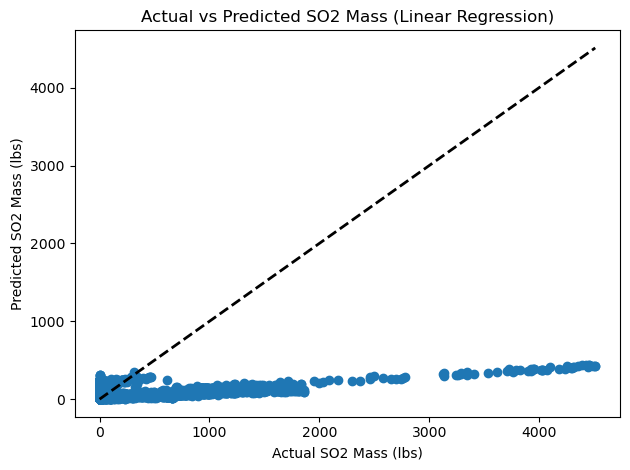

In [14]:
# default model (no lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

# correlation analysis showed virtually no linear relationships
# only spearman showed some monotonic ones

R^2 Score: 0.0539
Mean Squared Error (MSE): 2908.2411
Root Mean Squared Error (RMSE): 53.9281
Normalized RMSE (by std): 0.9733


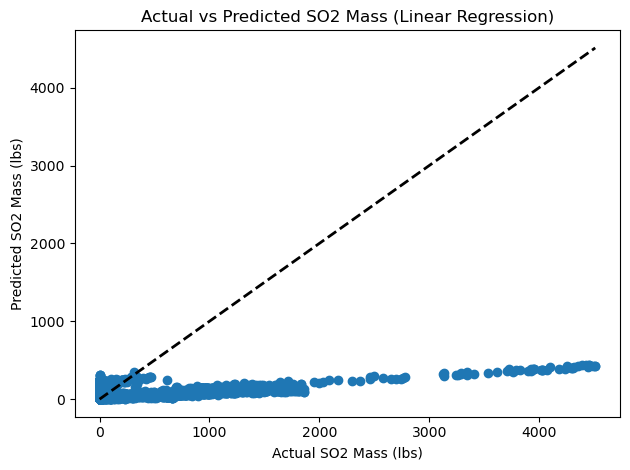

In [15]:
# default model (no lags, no unmeasured, with temps)

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h4>Median Imputation</h4>

In [19]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]

# use simple imputer to fill nan values with median (necessary for linear regression)
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', num_pipeline, num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

R^2 Score: 0.0244
Mean Squared Error (MSE): 2520.8891
Root Mean Squared Error (RMSE): 50.2085
Normalized RMSE (by std): 0.9883


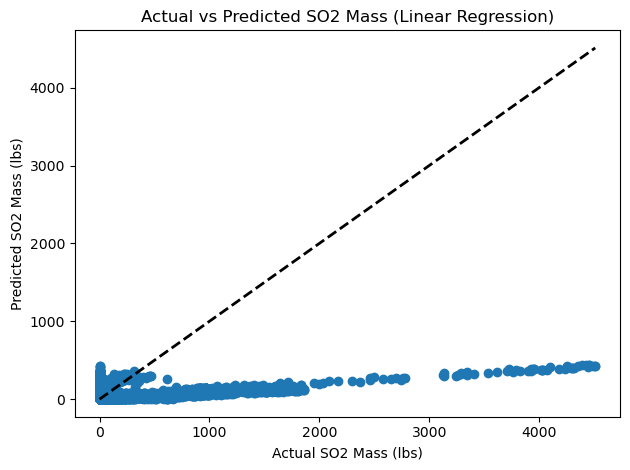

In [21]:
# default model (no lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

R^2 Score: 0.0245
Mean Squared Error (MSE): 2520.7881
Root Mean Squared Error (RMSE): 50.2075
Normalized RMSE (by std): 0.9883


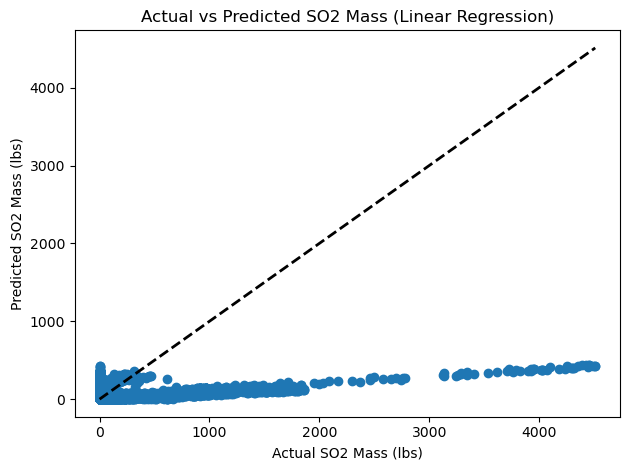

In [ ]:
# default model (no lags, no unmeasured, with temps)

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

# correlation analysis showed virtually no linear relationships
# only spearman showed some monotonic ones

<h4>With lags</h4>

In [ ]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) + lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]

# use simple imputer to fill nan values with median (necessary for linear regression)
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', num_pipeline, num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [23]:
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any NaN values
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

X_test = X_test.dropna(axis=0, how='any')  # drop rows with any NaN values
y_test = y_test[X_test.index]  # align y_train with X_train after dropping NaN rows

R^2 Score: 0.9528
Mean Squared Error (MSE): 121.9679
Root Mean Squared Error (RMSE): 11.0439
Normalized RMSE (by std): 0.2174


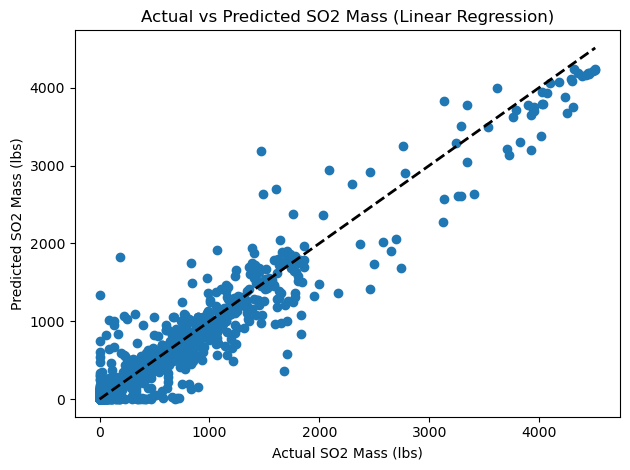

In [ ]:
# default model (no lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

R^2 Score: 0.9528
Mean Squared Error (MSE): 121.9679
Root Mean Squared Error (RMSE): 11.0439
Normalized RMSE (by std): 0.2174


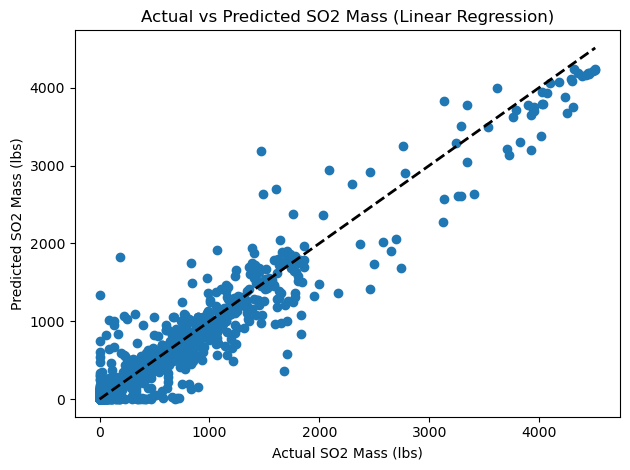

In [25]:
# default model (with lags, no unmeasured, with temps)

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h3>MLP</h3>

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [ ]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# we test two data strategies, 
# 1 imputing with median 
# removing nan cols with excessive number of nan vals otherwise removing respective nan rows

Gross Load (MW)              5.967985
Latitude                    10.302394
Longitude                   10.302394
Nameplate Capacity (MWe)    10.302394
hourly_capacity_factor       6.935827
hourly_ramping_factor       16.271541
Summer Capacity (MW)        58.785922
Winter Capacity (MW)        58.785922
Minimum Load (MW)           58.785922
Temperature (F)              1.696861
dtype: float64

<h4>No Imputation, remove nan cols/rows</h4>

In [ ]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3443122, 80), New shape: (2850950, 80)
Change in total rows: -592172


In [27]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                # 'Summer Capacity (MW)',
                # 'Winter Capacity (MW)', 
                # 'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [28]:
# mlp struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [29]:
X_sampled.shape

(477358, 114)

In [ ]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_sampled, y_sampled)

# using the sampled training data, this took 9mins

In [32]:
joblib.dump(mlp_default_model, "NY/Hourly/Concatted File/Modeling/MLP/SO2/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json", compress=True)

['NY/Hourly/Concatted File/Modeling/MLP/SO2/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json']

In [33]:
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.4776
Mean Squared Error (MSE): 1605.8331
Root Mean Squared Error (RMSE): 40.0728
Normalized RMSE (by std): 0.7233


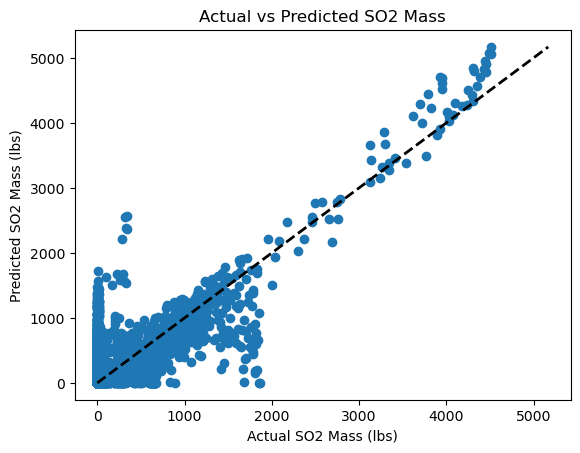

In [35]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h4>Median Imputation</h4>

In [36]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]

numeric_imputer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', numeric_imputer, num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [37]:
# mlp struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [ ]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_sampled, y_sampled)

# using the sampled training data, this took 11mins

joblib.dump(mlp_default_model, "NY/Hourly/Concatted File/Modeling/MLP/SO2/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps.json", compress=True)

In [39]:
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.7054
Mean Squared Error (MSE): 761.1297
Root Mean Squared Error (RMSE): 27.5886
Normalized RMSE (by std): 0.5431


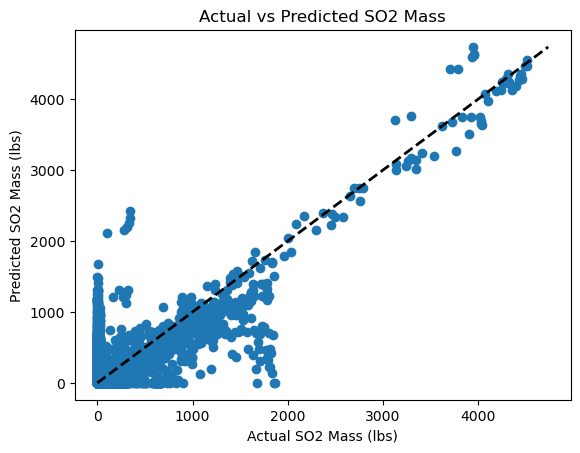

In [40]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h4>With Lags</h4>

In [41]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) + lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]

numeric_imputer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', numeric_imputer, num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
# some lag values may still be na so we remove those rows
X_train = X_train.dropna()
y_train = y_train[X_train.index]

In [47]:
# mlp struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [48]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_sampled, y_sampled)

# using the sampled training data, this took XYmins

joblib.dump(mlp_default_model, "NY/Hourly/Concatted File/Modeling/MLP/SO2/Trained Models/mlp_default_model_ny_with_lags_no_unmeasured_with_temps.json", compress=True)

['NY/Hourly/Concatted File/Modeling/MLP/SO2/Trained Models/mlp_default_model_ny_with_lags_no_unmeasured_with_temps.json']

In [49]:
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.9806
Mean Squared Error (MSE): 50.0251
Root Mean Squared Error (RMSE): 7.0728
Normalized RMSE (by std): 0.1392


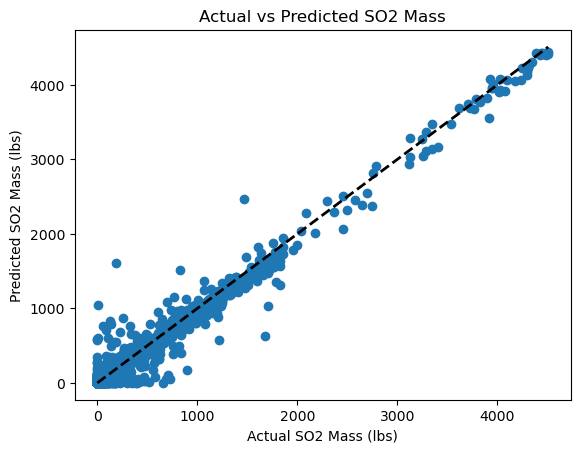

In [50]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>Random Forest</h3>

In [ ]:
# default params are:
# n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, 
# min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
# max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
#  n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, 
# ccp_alpha=0.0, max_samples=None, monotonic_cst=None

In [3]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [4]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [5]:
# rf struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [6]:
X_sampled.shape

(577791, 121)

In [7]:
# still takes approx. 3 mins to compute

rf_model_no_lags = RandomForestRegressor(random_state=42, n_jobs=-1) # max_depth=5 without max depth it takes very long

# Train Random Forest model with default parameters
rf_model_no_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [8]:
joblib.dump(rf_model_no_lags, "NY/Hourly/Concatted File/Modeling/RF/SO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

['NY/Hourly/Concatted File/Modeling/RF/SO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json']

In [ ]:
rf_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/SO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

R^2 Score: 0.7780
Mean Squared Error (MSE): 573.5268
Root Mean Squared Error (RMSE): 23.9484
Normalized RMSE (by std): 0.4714


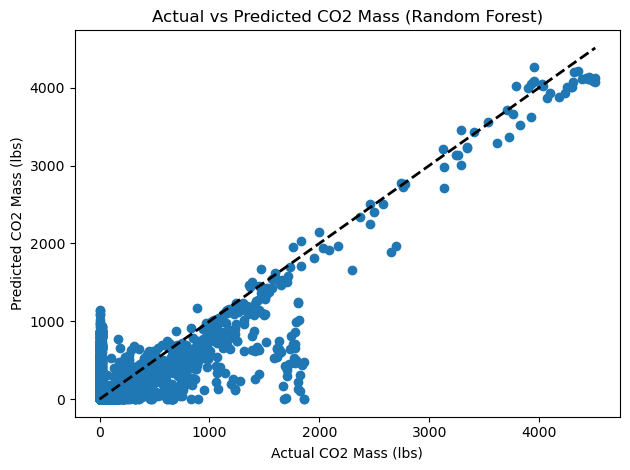

In [ ]:
# default model (no lags, no unmeasured data, with temps)

y_pred = rf_model_no_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

In [ ]:
# even with downsampling takes approx. 4 mins to compute

rf_model_with_lags = RandomForestRegressor(random_state=42, n_jobs=-1) # max_depth=5 without max depth it takes very long

rf_model_with_lags.fit(X_sampled, y_sampled.values.ravel())

joblib.dump(rf_model_with_lags, "NY/Hourly/Concatted File/Modeling/RF/SO2/Trained Models/rf_default_model_ny_with_lags_no_unmeasured_with_temps.json")

In [ ]:
rf_model_with_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/SO2/Trained Models/rf_default_model_ny_with_lags_with_unmeasured_with_temps.json")

R^2 Score: 0.9828
Mean Squared Error (MSE): 44.4147
Root Mean Squared Error (RMSE): 6.6644
Normalized RMSE (by std): 0.1312


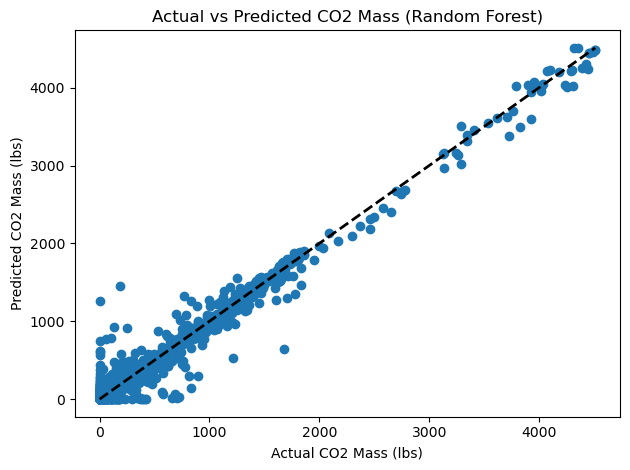

In [ ]:
# default model (with lags, no unmeasured data, with temps)

y_pred = rf_model_with_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h3>XGBoost</h3>

<h5>Preprocessing Methods</h5>

In [3]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # Combine the two dfs
    df = pd.concat([df, previous_year_df])

    # Set datetime as the index for time-series operations
    df = df.set_index("datetime")

    # Sort the DataFrame by the datetime index to ensure proper alignment
    df = df.sort_index()

    # Sort the DataFrame by Facility ID, Unit ID, and datetime to ensure proper alignment
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # Apply the lag feature function to each group
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # Filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime(df["Date"].astype(str) + ' ' + df["Hour"].astype(str).str.zfill(2) + ":00:00")


    return df


In [4]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # Split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # Concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_ny, ny_code_cols = preprocess_program_codes(campd_ny)
# ny_code_cols

<h5>Full Model Train and Test</h5>

<h6>Preprocessing</h6>

In [6]:
campd_ny["Day"] = campd_ny["datetime"].dt.day

In [7]:
# read in previous year to get according lags
campd_ny_2018 = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2018-ny.csv", dtype=campd_type_dict, date_format=["Date"])
campd_ny_2018 = campd_ny_2018[["Facility ID", "Unit ID", "Date", "Hour", "SO2 Mass (lbs)"]]
campd_ny_2018["datetime"] = pd.to_datetime(campd_ny_2018["Date"].astype(str) + ' ' + campd_ny_2018["Hour"].astype(str).str.zfill(2) + ":00:00")
campd_ny_2018["SO2 Mass (lbs)"] = campd_ny_2018["SO2 Mass (lbs)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_ny, campd_ny_2018, "SO2 Mass (lbs)")

C:\Users\marce\AppData\Local\Temp\ipykernel_37924\3620203290.py:2: DtypeWarning: Columns (4,19,21,28,29,30) have mixed types. Specify dtype option on import or set low_memory=False.
  campd_ny_2018 = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2018-ny.csv", dtype=campd_type_dict, date_format=["Date"])
C:\Users\marce\AppData\Local\Temp\ipykernel_37924\2313467750.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
C:\Users\marce\AppData\Local\Temp\ipykernel_37924\2313467750.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent a

In [8]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_with_SO2_lags.csv", index=False)

In [9]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_with_SO2_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [10]:
# manually one-hot encode program codes
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [11]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [12]:
# Randomly remove a fraction of rows where Operating Time is 0.
def downsample_zero_operating_time(df, frac_to_remove=0.9, random_state=42):
    # create dfs for those with and without operating time
    zero_op = df[df["Operating Time"] == 0]
    non_zero_op = df[df["Operating Time"] != 0]

    # remove sample of rows
    drop_sample = zero_op.sample(frac=frac_to_remove, random_state=random_state)
    kept_zero_op = zero_op.drop(index=drop_sample.index)
    df_downsampled = pd.concat([non_zero_op, kept_zero_op]).sort_index()

    return df_downsampled


In [13]:
campd_df.shape

(14028675, 80)

In [14]:
# Downsample 90% of the nonOperating data (should be fine since xgb does not require continuity unlike e. g. LSTM)
campd_df = downsample_zero_operating_time(campd_df)

In [15]:
campd_df.shape

(3563498, 80)

In [16]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", dtype=campd_type_dict)

In [17]:
campd_df["SO2 Mass Measure Indicator"].value_counts()

SO2 Mass Measure Indicator
Measured                   2280325
Nothing                    1162797
LME                          72482
Substitute                   31730
Measured and Substitute      16164
Name: count, dtype: Int64

In [18]:
campd_df = campd_df[(campd_df["SO2 Mass Measure Indicator"] == "Measured") | (campd_df["SO2 Mass Measure Indicator"] == "Nothing")]
campd_df["SO2 Mass Measure Indicator"].value_counts()

SO2 Mass Measure Indicator
Measured    2280325
Nothing     1162797
Name: count, dtype: Int64

In [19]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", index=False)

In [3]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [96]:

pd.set_option('display.max_columns', None)
campd_df["Calc SO2 emission rate (pounds per hour)"] = np.nan
campd_df.loc[campd_df["Primary Fuel Type"] == "Pipeline Natural Gas", "Calc SO2 emission rate (pounds per hour)"] = 0.0006 * campd_df["Heat Input (mmBtu)"]
campd_df["Difference Calc/Meas"] = campd_df["SO2 Mass (lbs)"] - campd_df["Calc SO2 emission rate (pounds per hour)"]
#campd_df.sort_values(by="Difference Calc/Meas", ascending=False).head()

In [ ]:

# Recalculate predicted SO2 emission rate only for Pipeline Natural Gas
campd_df["Calc SO2 emission rate (pounds per hour)"] = np.nan
campd_df.loc[
    campd_df["Primary Fuel Type"] == "Pipeline Natural Gas",
    "Calc SO2 emission rate (pounds per hour)"
] = 0.0006 * campd_df["Heat Input (mmBtu)"]

# Calculate difference
campd_df["Difference Calc/Meas"] = (
    campd_df["SO2 Mass (lbs)"] - campd_df["Calc SO2 emission rate (pounds per hour)"]
)

# Filter for Pipeline Natural Gas and SO2 values < 100 lbs
mask = (
    (campd_df["Primary Fuel Type"] == "Pipeline Natural Gas") &
    (campd_df["SO2 Mass (lbs)"] < 3) &
    (campd_df["Calc SO2 emission rate (pounds per hour)"] < 3) &
    (campd_df["Year"] == 2019)
)

filtered_df = campd_df[mask]

# Scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(
    filtered_df["SO2 Mass (lbs)"],
    filtered_df["Calc SO2 emission rate (pounds per hour)"]
)
plt.xlabel("Actual SO₂ Mass (lbs)")
plt.ylabel("Calculated SO₂ Emission Rate (lbs/hr)")
plt.title("Actual vs Predicted SO₂ Mass")

# 1:1 reference line
min_val = min(filtered_df["SO2 Mass (lbs)"].min(), filtered_df["Calc SO2 emission rate (pounds per hour)"].min())
max_val = max(filtered_df["SO2 Mass (lbs)"].max(), filtered_df["Calc SO2 emission rate (pounds per hour)"].max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)

plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate performance
r2 = r2_score(filtered_df["SO2 Mass (lbs)"], filtered_df["Calc SO2 emission rate (pounds per hour)"])
mse = mean_squared_error(filtered_df["SO2 Mass (lbs)"], filtered_df["Calc SO2 emission rate (pounds per hour)"])
rmse = np.sqrt(mse)
nrmse = rmse / np.std(filtered_df["SO2 Mass (lbs)"])

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Normalized RMSE (by std): {nrmse:.4f}")

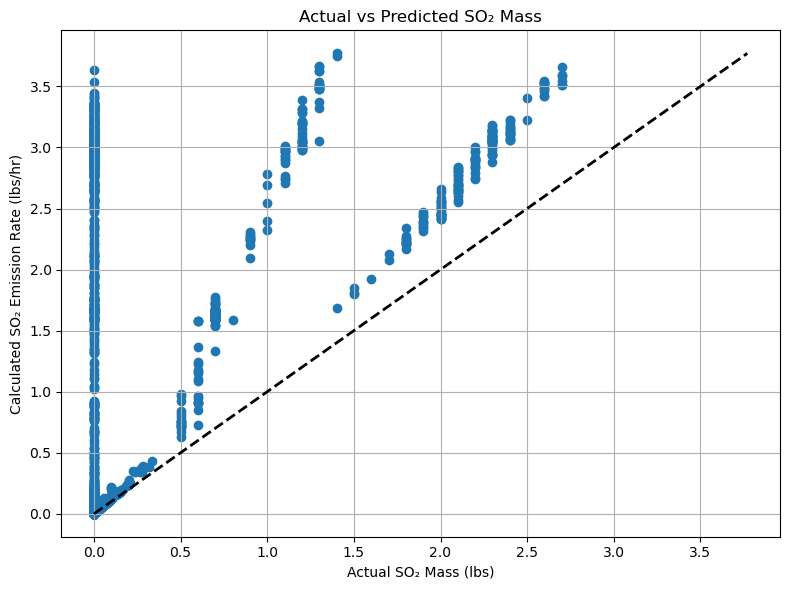

R² Score: -3.0052
Mean Squared Error (MSE): 0.0061
Root Mean Squared Error (RMSE): 0.0778
Normalized RMSE (by std): 2.0025


In [ ]:

# Recalculate predicted SO2 emission rate only for Pipeline Natural Gas
campd_df["Calc SO2 emission rate (pounds per hour)"] = np.nan
campd_df.loc[
    campd_df["Primary Fuel Type"] == "Pipeline Natural Gas",
    "Calc SO2 emission rate (pounds per hour)"
] = 0.0006 * campd_df["Heat Input (mmBtu)"]

# Calculate difference
campd_df["Difference Calc/Meas"] = (
    campd_df["SO2 Mass (lbs)"] - campd_df["Calc SO2 emission rate (pounds per hour)"]
)

# Filter for Pipeline Natural Gas and SO2 values
mask = (
    (campd_df["Primary Fuel Type"] == "Pipeline Natural Gas") &
    (campd_df["SO2 Rate (lbs/mmBtu)"] < 0.001)
)

filtered_df = campd_df[mask]

# Scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(
    filtered_df["SO2 Mass (lbs)"],
    filtered_df["Calc SO2 emission rate (pounds per hour)"]
)
plt.xlabel("Actual SO₂ Mass (lbs)")
plt.ylabel("Calculated SO₂ Emission Rate (lbs/hr)")
plt.title("Actual vs Predicted SO₂ Mass")

# 1:1 reference line
min_val = min(filtered_df["SO2 Mass (lbs)"].min(), filtered_df["Calc SO2 emission rate (pounds per hour)"].min())
max_val = max(filtered_df["SO2 Mass (lbs)"].max(), filtered_df["Calc SO2 emission rate (pounds per hour)"].max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)

plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate performance
r2 = r2_score(filtered_df["SO2 Mass (lbs)"], filtered_df["Calc SO2 emission rate (pounds per hour)"])
mse = mean_squared_error(filtered_df["SO2 Mass (lbs)"], filtered_df["Calc SO2 emission rate (pounds per hour)"])
rmse = np.sqrt(mse)
nrmse = rmse / np.std(filtered_df["SO2 Mass (lbs)"])

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Normalized RMSE (by std): {nrmse:.4f}")

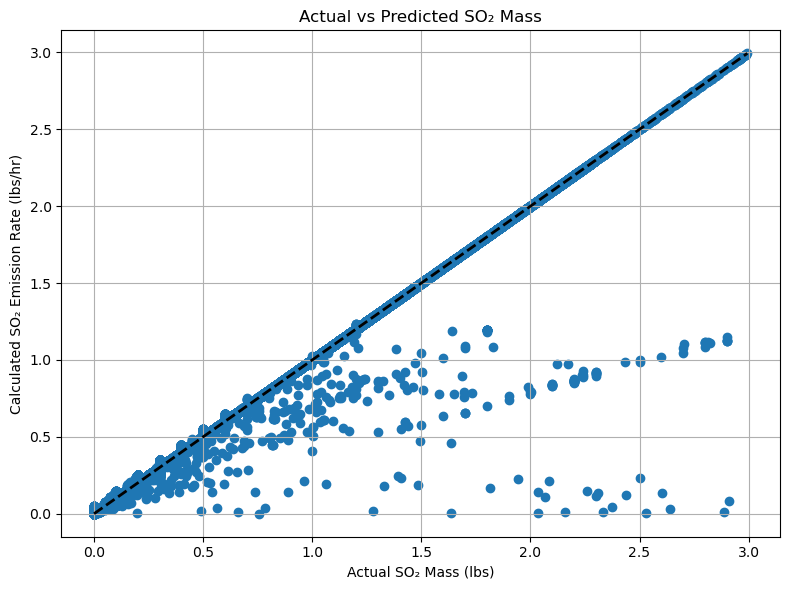

R² Score: 0.9978
Mean Squared Error (MSE): 0.0006
Root Mean Squared Error (RMSE): 0.0246
Normalized RMSE (by std): 0.0474


In [42]:

# Recalculate predicted SO2 emission rate only for Pipeline Natural Gas
campd_df["Calc SO2 emission rate (pounds per hour)"] = np.nan
campd_df.loc[
    campd_df["Primary Fuel Type"] == "Pipeline Natural Gas",
    "Calc SO2 emission rate (pounds per hour)"
] = 0.0006 * campd_df["Heat Input (mmBtu)"]

# Calculate difference
campd_df["Difference Calc/Meas"] = (
    campd_df["SO2 Mass (lbs)"] - campd_df["Calc SO2 emission rate (pounds per hour)"]
)

# Filter for Pipeline Natural Gas and SO2 values < 100 lbs
mask = (
    (campd_df["Primary Fuel Type"] == "Pipeline Natural Gas") &
    (campd_df["SO2 Mass (lbs)"] < 3) &
    (campd_df["Calc SO2 emission rate (pounds per hour)"] < 3) &
    (campd_df["Year"] == 2024)
    )

filtered_df = campd_df[mask]

# Scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(
    filtered_df["SO2 Mass (lbs)"],
    filtered_df["Calc SO2 emission rate (pounds per hour)"]
)
plt.xlabel("Actual SO₂ Mass (lbs)")
plt.ylabel("Calculated SO₂ Emission Rate (lbs/hr)")
plt.title("Actual vs Predicted SO₂ Mass")

# 1:1 reference line
min_val = min(filtered_df["SO2 Mass (lbs)"].min(), filtered_df["Calc SO2 emission rate (pounds per hour)"].min())
max_val = max(filtered_df["SO2 Mass (lbs)"].max(), filtered_df["Calc SO2 emission rate (pounds per hour)"].max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)

plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate performance
r2 = r2_score(filtered_df["SO2 Mass (lbs)"], filtered_df["Calc SO2 emission rate (pounds per hour)"])
mse = mean_squared_error(filtered_df["SO2 Mass (lbs)"], filtered_df["Calc SO2 emission rate (pounds per hour)"])
rmse = np.sqrt(mse)
nrmse = rmse / np.std(filtered_df["SO2 Mass (lbs)"])

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Normalized RMSE (by std): {nrmse:.4f}")

In [7]:
pd.set_option('display.float_format', '{:.2f}'.format)

campd_df["SO2 Mass (lbs)"].describe()

count   3443122.00
mean          4.82
std          80.71
min           0.00
25%           0.00
50%           0.29
75%           0.99
max        5029.30
Name: SO2 Mass (lbs), dtype: float64

In [ ]:
# Split the data
below_3 = filtered_df[filtered_df["SO2 Mass (lbs)"] < 3]
above_3 = filtered_df[filtered_df["SO2 Mass (lbs)"] >= 3]

# Define a function to compute metrics
def evaluate_performance(df, label):
    y_true = df["SO2 Mass (lbs)"]
    y_pred = df["Calc SO2 emission rate (pounds per hour)"]
    
    if len(df) == 0:
        print(f"\n{label}: No data points.")
        return
    
    r2 = r2_score(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse / np.std(y_true)

    print(f"\n{label}")
    print(f"R² Score: {r2:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"Normalized RMSE (by std): {nrmse:.4f}")

# Evaluate both subsets
evaluate_performance(below_3, "SO₂ < 3 lbs")
evaluate_performance(above_3, "SO₂ ≥ 3 lbs")

# formula performs well below 3 lbs, but it is very mixed (see above), we cannot accurately discern whether oil was used, and filtering by 
# realistic gas SO2 rates is not possible since they vary greatly


SO₂ < 3 lbs
R² Score: 0.9880
Mean Squared Error (MSE): 0.0028
Root Mean Squared Error (RMSE): 0.0526
Normalized RMSE (by std): 0.1096

SO₂ ≥ 3 lbs
R² Score: -0.2930
Mean Squared Error (MSE): 133950.7541
Root Mean Squared Error (RMSE): 365.9928
Normalized RMSE (by std): 1.1371


In [14]:
campd_df[(campd_df["Heat Input (mmBtu)"] == campd_df[(campd_df["Primary Fuel Type"] == "Pipeline Natural Gas") & (campd_df["Year"] == 2019)]["Heat Input (mmBtu)"].max())]

,datetime,State,Facility Name,Facility ID,Unit ID,Date,Hour,Operating Time,Gross Load (MW),Steam Load (1000 lb/hr),SO2 Mass (lbs),SO2 Mass Measure Indicator,SO2 Rate (lbs/mmBtu),SO2 Rate Measure Indicator,CO2 Mass (short tons),CO2 Mass Measure Indicator,CO2 Rate (short tons/mmBtu),CO2 Rate Measure Indicator,NOx Mass (lbs),NOx Mass Measure Indicator,NOx Rate (lbs/mmBtu),NOx Rate Measure Indicator,Heat Input (mmBtu),Heat Input Measure Indicator,Primary Fuel Type,Secondary Fuel Type,Unit Type,SO2 Controls,NOx Controls,Program Code,Year,Source Category,Latitude,Longitude,SO2 Phase,NOx Phase,Operating Status,Max Hourly HI Rate (mmBtu/hr),Associated Generators & Nameplate Capacity (MWe),Nameplate Capacity (MWe),Month,hourly_capacity_factor,hourly_ramping_factor,Summer Capacity (MW),Winter Capacity (MW),Minimum Load (MW),Operating Year_min,Operating Year_max,Operating Year_mean,Planned Retirement Year,unit_age_min,unit_age_max,unit_age_mean,Day,Nearest_Station,Temperature (F),lag_1_hour,lag_2_hours,lag_1_day,lag_2_days,lag_1_week,lag_1_month,lag_1_year,ARP,CSNOX,CSOSG2,CSOSG2E,CSOSG3,CSSO2G1,MATS,Missing,NSPS4T,RGGI,SIPNOX,Hour_sin,Hour_cos,Day_sin,Day_cos,Month_sin,Month_cos,Calc SO2 emission rate (pounds per hour),Difference Calc/Meas
477825,2019-08-09 13:00:00,NY,Ravenswood Generating Station,2500,30,2019-08-09,13,1.00,988.00,NaN,5.58,Measured,0.00,Calculated,552.60,Measured,0.06,Calculated,892.60,Measured,0.10,Measured,9298.10,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,Nothing,"ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Electric Utility,40.76,-73.95,Phase 2,Nothing,Operating,9379.00,3 (1027.7),1027.70,8,0.96,-0.00,988.50,977.80,150.00,1965.00,1965.00,1965.00,<NA>,54,54,54.00,9.00,NYC,80.00,5.58,5.55,0.21,0.00,0.00,0.00,4.15,1,1,1,0,0,1,1,0,0,1,0,-0.26,-0.97,0.97,-0.22,-0.87,-0.50,5.58,0.00


In [16]:
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [25]:
campd_df[campd_df["Primary Fuel Type"] == "Pipeline Natural Gas"]["SO2 Rate (lbs/mmBtu)"].describe()

count   2881575.0000
mean          0.0024
std           0.0280
min           0.0000
25%           0.0000
50%           0.0010
75%           0.0010
max          11.8000
Name: SO2 Rate (lbs/mmBtu), dtype: float64

In [ ]:
campd_df[(campd_df["Facility ID"] == 2516) & (campd_df["Unit ID"] == "4") & (campd_df["datetime"].dt.date == pd.to_datetime("2019-12-19").date())].sort_values(by="datetime")


# large shift in SO2 Rate (and SO2 and SO2 rate) -> likely fuel switch to oil
# big jump in SO2 emissions
# -> we want to exclude these unrealistically high rates for gas SO2 prediction

,datetime,State,Facility Name,Facility ID,Unit ID,Date,Hour,Operating Time,Gross Load (MW),Steam Load (1000 lb/hr),SO2 Mass (lbs),SO2 Mass Measure Indicator,SO2 Rate (lbs/mmBtu),SO2 Rate Measure Indicator,CO2 Mass (short tons),CO2 Mass Measure Indicator,CO2 Rate (short tons/mmBtu),CO2 Rate Measure Indicator,NOx Mass (lbs),NOx Mass Measure Indicator,NOx Rate (lbs/mmBtu),NOx Rate Measure Indicator,Heat Input (mmBtu),Heat Input Measure Indicator,Primary Fuel Type,Secondary Fuel Type,Unit Type,SO2 Controls,NOx Controls,Program Code,Year,Source Category,Latitude,Longitude,SO2 Phase,NOx Phase,Operating Status,Max Hourly HI Rate (mmBtu/hr),Associated Generators & Nameplate Capacity (MWe),Nameplate Capacity (MWe),Month,hourly_capacity_factor,hourly_ramping_factor,Summer Capacity (MW),Winter Capacity (MW),Minimum Load (MW),Operating Year_min,Operating Year_max,Operating Year_mean,Planned Retirement Year,unit_age_min,unit_age_max,unit_age_mean,Day,Nearest_Station,Temperature (F),lag_1_hour,lag_2_hours,lag_1_day,lag_2_days,lag_1_week,lag_1_month,lag_1_year,ARP,CSNOX,CSOSG2,CSOSG2E,CSOSG3,CSSO2G1,MATS,Missing,NSPS4T,RGGI,SIPNOX,Hour_sin,Hour_cos,Day_sin,Day_cos,Month_sin,Month_cos,Calc SO2 emission rate (pounds per hour),Difference Calc/Meas
894494,2019-12-19 00:00:00,NY,Northport,2516,4,2019-12-19,0,1.00,161.00,NaN,1.09,Measured,0.00,Calculated,107.70,Measured,0.06,Calculated,56.20,Measured,0.03,Measured,1812.90,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,"Overfire Air,Low NOx Burner Technology w/ Sepa...","ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Electric Utility,40.92,-73.34,Phase 2,Nothing,Operating,3800.00,4 (387),387.00,12,0.42,0.05,398.00,396.50,40.00,1977.00,1977.00,1977.00,<NA>,42,42,42.00,19.00,FRG,19.90,0.96,0.89,1.06,0.91,1.15,0.00,0.00,1,1,1,0,0,1,1,0,0,1,0,0.00,1.00,-0.97,-0.22,-0.00,1.00,1.09,0.00
894495,2019-12-19 01:00:00,NY,Northport,2516,4,2019-12-19,1,1.00,190.00,NaN,1.26,Measured,0.00,Calculated,124.90,Measured,0.06,Calculated,79.90,Measured,0.04,Measured,2102.30,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,"Overfire Air,Low NOx Burner Technology w/ Sepa...","ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Electric Utility,40.92,-73.34,Phase 2,Nothing,Operating,3800.00,4 (387),387.00,12,0.49,0.07,398.00,396.50,40.00,1977.00,1977.00,1977.00,<NA>,42,42,42.00,19.00,FRG,19.90,1.09,0.96,1.06,0.90,0.97,0.00,0.00,1,1,1,0,0,1,1,0,0,1,0,0.26,0.97,-0.97,-0.22,-0.00,1.00,1.26,-0.00
894496,2019-12-19 02:00:00,NY,Northport,2516,4,2019-12-19,2,1.00,190.00,NaN,1.26,Measured,0.00,Calculated,125.10,Measured,0.06,Calculated,80.00,Measured,0.04,Measured,2104.40,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,"Overfire Air,Low NOx Burner Technology w/ Sepa...","ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Electric Utility,40.92,-73.34,Phase 2,Nothing,Operating,3800.00,4 (387),387.00,12,0.49,0.00,398.00,396.50,40.00,1977.00,1977.00,1977.00,<NA>,42,42,42.00,19.00,FRG,18.00,1.26,1.09,1.04,0.89,0.97,0.00,0.00,1,1,1,0,0,1,1,0,0,1,0,0.50,0.87,-0.97,-0.22,-0.00,1.00,1.26,0.00
894497,2019-12-19 03:00:00,NY,Northport,2516,4,2019-12-19,3,1.00,190.00,NaN,1.27,Measured,0.00,Calculated,125.90,Measured,0.06,Calculated,80.50,Measured,0.04,Measured,2118.70,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,"Overfire Air,Low NOx Burner Technology w/ Sepa...","ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Electric Utility,40.92,-73.34,Phase 2,Nothing,Operating,3800.00,4 (387),387.00,12,0.49,0.00,398.00,396.50,40.00,1977.00,1977.00,1977.00,<NA>,42,42,42.00,19.00,FRG,18.00,1.26,1.26,1.04,1.20,0.98,0.00,0.00,1,1,1,0,0,1,1,0,0,1,0,0.71,0.71,-0.97,-0.22,-0.00,1.00,1.27,-0.00
894498,2019-12-19 04:00:00,NY,Northport,2516,4,2019-12-19,4,1.00,212.00,NaN,1.41,Measured,0.00,Calculated,139.50,Measured,0.06,Calculated,91.50,Measured,0.04,Measured,2347.00,Measured,Pipeline Natural Gas,Residual Oil,Tangentially-fired,Nothing,"Overfire Air,Low NOx Burner Technology w/ Sepa..."

In [31]:
pd.set_option('display.max_columns', None)
filtered_df.sort_values(by="Difference Calc/Meas").head(3)

,datetime,State,Facility Name,Facility ID,Unit ID,Date,Hour,Operating Time,Gross Load (MW),Steam Load (1000 lb/hr),SO2 Mass (lbs),SO2 Mass Measure Indicator,SO2 Rate (lbs/mmBtu),SO2 Rate Measure Indicator,CO2 Mass (short tons),CO2 Mass Measure Indicator,CO2 Rate (short tons/mmBtu),CO2 Rate Measure Indicator,NOx Mass (lbs),NOx Mass Measure Indicator,NOx Rate (lbs/mmBtu),NOx Rate Measure Indicator,Heat Input (mmBtu),Heat Input Measure Indicator,Primary Fuel Type,Secondary Fuel Type,Unit Type,SO2 Controls,NOx Controls,Program Code,Year,Source Category,Latitude,Longitude,SO2 Phase,NOx Phase,Operating Status,Max Hourly HI Rate (mmBtu/hr),Associated Generators & Nameplate Capacity (MWe),Nameplate Capacity (MWe),Month,hourly_capacity_factor,hourly_ramping_factor,Summer Capacity (MW),Winter Capacity (MW),Minimum Load (MW),Operating Year_min,Operating Year_max,Operating Year_mean,Planned Retirement Year,unit_age_min,unit_age_max,unit_age_mean,Day,Nearest_Station,Temperature (F),lag_1_hour,lag_2_hours,lag_1_day,lag_2_days,lag_1_week,lag_1_month,lag_1_year,ARP,CSNOX,CSOSG2,CSOSG2E,CSOSG3,CSSO2G1,MATS,Missing,NSPS4T,RGGI,SIPNOX,Hour_sin,Hour_cos,Day_sin,Day_cos,Month_sin,Month_cos,Calc SO2 emission rate (pounds per hour),Difference Calc/Meas
1197321,2020-06-10 18:00:00,NY,Bowline Generating Station,2625,2,2020-06-10,18,1.0000,567.0000,NaN,0.0000,Measured,0.0000,Calculated,358.9000,Measured,0.0590,Calculated,829.5000,Measured,0.1370,Measured,6055.1000,Measured,Pipeline Natural Gas,Residual Oil,Dry bottom wall-fired boiler,Nothing,Overfire Air,"ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2020,Electric Utility,41.2044,-73.9689,Phase 2,Nothing,Operating,7600.0000,2 (640),640.0000,6,0.8859,0.0000,562.0000,567.0000,100.0000,1974.0000,1974.0000,1974.0000,<NA>,46,46,46.0000,10.0000,HPN,73.0000,1.3000,1.3000,2.5000,0.0000,0.0000,0.0000,0.0000,1,1,1,0,0,1,1,0,0,1,0,-1.0000,-0.0000,0.4339,-0.9010,0.0000,-1.0000,3.6331,-3.6331
1200830,2022-02-03 15:00:00,NY,Bowline Generating Station,2625,2,2022-02-03,15,1.0000,535.0000,NaN,0.0000,Measured,0.0000,Calculated,349.6000,Measured,0.0590,Calculated,725.3000,Measured,0.1230,Measured,5896.8000,Measured,Pipeline Natural Gas,Residual Oil,Dry bottom wall-fired boiler,Nothing,Overfire Air,"ARP, CSNOX, CSOSG3, CSSO2G1, MATS, RGGI",2022,Electric Utility,41.2044,-73.9689,Phase 2,Nothing,Operating,7600.0000,2 (640),640.0000,2,0.8359,0.0281,573.6000,568.8000,100.0000,1974.0000,1974.0000,1974.0000,<NA>,48,48,48.0000,3.0000,HPN,42.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1,1,0,0,1,1,1,0,0,1,0,-0.7071,-0.7071,0.4339,-0.9010,0.8660,0.5000,3.5381,-3.5381
1200745,2022-01-28 00:00:00,NY,Bowline Generating Station,2625,2,2022-01-28,0,1.0000,555.0000,NaN,0.0000,Measured,0.0000,Calculated,340.1000,Measured,0.0590,Calculated,682.8000,Measured,0.1190,Measured,5737.5000,Measured,Pipeline Natural Gas,Residual Oil,Dry bottom wall-fired boiler,Nothing,Overfire Air,"ARP, CSNOX, CSOSG3, CSSO2G1, MATS, RGGI",2022,Electric Utility,41.2044,-73.9689,Phase 2,Nothing,Operating,7600.0000,2 (640),640.0000,1,0.8672,0.0219,573.6000,568.8000,100.0000,1974.0000,1974.0000,1974.0000,<NA>,48,48,48.0000,28.0000,HPN,28.0000,0.0000,0.0000,0.0000,8.4000,7.3000,0.0000,24.4000,1,1,0,0,1,1,1,0,0,1,0,0.0000,1.0000,-0.0000,1.0000,0.5000,0.8660,3.4425,-3.4425


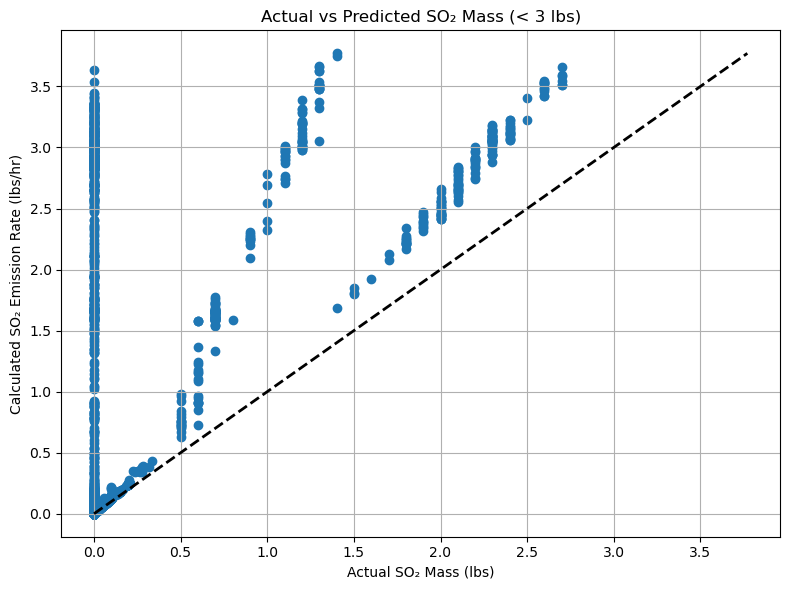

R² Score: -3.0052
Mean Squared Error (MSE): 0.0061
Root Mean Squared Error (RMSE): 0.0778
Normalized RMSE (by std): 2.0025


In [ ]:

# Recalculate predicted SO2 emission rate only for Pipeline Natural Gas
campd_df["Calc SO2 emission rate (pounds per hour)"] = np.nan
campd_df.loc[
    campd_df["Primary Fuel Type"] == "Pipeline Natural Gas",
    "Calc SO2 emission rate (pounds per hour)"
] = 0.0006 * campd_df["Heat Input (mmBtu)"]

# Calculate difference
campd_df["Difference Calc/Meas"] = (
    campd_df["SO2 Mass (lbs)"] - campd_df["Calc SO2 emission rate (pounds per hour)"]
)

# Filter for Pipeline Natural Gas and SO2 rates < 0.001 lbs/mmBtu
mask = (
    (campd_df["Primary Fuel Type"] == "Pipeline Natural Gas") &
    (campd_df["SO2 Rate (lbs/mmBtu)"] < 0.001) 
)

filtered_df = campd_df[mask]

# Scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(
    filtered_df["SO2 Mass (lbs)"],
    filtered_df["Calc SO2 emission rate (pounds per hour)"]
)
plt.xlabel("Actual SO₂ Mass (lbs)")
plt.ylabel("Calculated SO₂ Emission Rate (lbs/hr)")
#plt.title("Actual vs Predicted SO₂ Mass (< 3 lbs)")

# 1:1 reference line
min_val = min(filtered_df["SO2 Mass (lbs)"].min(), filtered_df["Calc SO2 emission rate (pounds per hour)"].min())
max_val = max(filtered_df["SO2 Mass (lbs)"].max(), filtered_df["Calc SO2 emission rate (pounds per hour)"].max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)

plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate performance
r2 = r2_score(filtered_df["SO2 Mass (lbs)"], filtered_df["Calc SO2 emission rate (pounds per hour)"])
mse = mean_squared_error(filtered_df["SO2 Mass (lbs)"], filtered_df["Calc SO2 emission rate (pounds per hour)"])
rmse = np.sqrt(mse)
nrmse = rmse / np.std(filtered_df["SO2 Mass (lbs)"])

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Normalized RMSE (by std): {nrmse:.4f}")

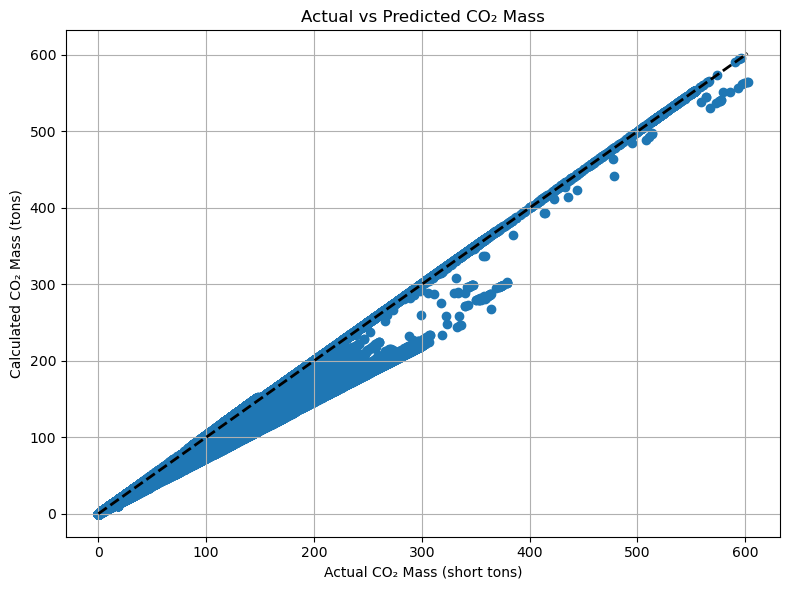

R² Score: 0.9975
Mean Squared Error (MSE): 7.1270
Root Mean Squared Error (RMSE): 2.6696
Normalized RMSE (by std): 0.0505


In [ ]:

# Define actual and predicted values
y_actual = campd_df["SO2 Mass (short tons)"]
y_predicted = campd_df["Calc SO2 emission rate (tons)"]

# Drop rows with NaNs in either column
valid_mask = y_actual.notna() & y_predicted.notna()
y_actual_clean = y_actual[valid_mask]
y_predicted_clean = y_predicted[valid_mask]

# Scatter plot: Actual vs Predicted SO2 Mass
plt.figure(figsize=(8, 6))
plt.scatter(y_actual_clean, y_predicted_clean)
plt.xlabel("Actual CO₂ Mass (short tons)")
plt.ylabel("Calculated CO₂ Mass (tons)")
plt.title("Actual vs Predicted CO₂ Mass")

# 1:1 reference line
min_val = min(y_actual_clean.min(), y_predicted_clean.min())
max_val = max(y_actual_clean.max(), y_predicted_clean.max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)

plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate performance
r2 = r2_score(y_actual_clean, y_predicted_clean)
mse = mean_squared_error(y_actual_clean, y_predicted_clean)
rmse = np.sqrt(mse)
nrmse = rmse / np.std(y_actual_clean)

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Normalized RMSE (by std): {nrmse:.4f}")

In [ ]:

pd.set_option('display.max_columns', None)

# https://www.ecfr.gov/current/title-40/chapter-I/subchapter-C/part-75/appendix-Appendix%20G%20to%20Part%2075
# Eq. G-4

campd_df.loc[
    campd_df["Primary Fuel Type"] == "Pipeline Natural Gas",
    "Calc SO2 emission rate (tons)"
] = (44 * 1040 * campd_df["Heat Input (mmBtu)"] * (1 / 385)) / 2000
campd_df["Difference Calc/Meas SO2"] = campd_df["SO2 Mass (short tons)"] - campd_df["Calc SO2 emission rate (tons)"]
campd_df.head()

# measured short tons: 110.10
# calc tons: 1.11

,datetime,State,Facility Name,Facility ID,Unit ID,Date,Hour,Operating Time,Gross Load (MW),Steam Load (1000 lb/hr),SO2 Mass (lbs),SO2 Mass Measure Indicator,SO2 Rate (lbs/mmBtu),SO2 Rate Measure Indicator,CO2 Mass (short tons),CO2 Mass Measure Indicator,CO2 Rate (short tons/mmBtu),CO2 Rate Measure Indicator,NOx Mass (lbs),NOx Mass Measure Indicator,NOx Rate (lbs/mmBtu),NOx Rate Measure Indicator,Heat Input (mmBtu),Heat Input Measure Indicator,Primary Fuel Type,Secondary Fuel Type,Unit Type,SO2 Controls,NOx Controls,Program Code,Year,Source Category,Latitude,Longitude,SO2 Phase,NOx Phase,Operating Status,Max Hourly HI Rate (mmBtu/hr),Associated Generators & Nameplate Capacity (MWe),Nameplate Capacity (MWe),Month,hourly_capacity_factor,hourly_ramping_factor,Summer Capacity (MW),Winter Capacity (MW),Minimum Load (MW),Operating Year_min,Operating Year_max,Operating Year_mean,Planned Retirement Year,unit_age_min,unit_age_max,unit_age_mean,Day,Nearest_Station,Temperature (F),lag_1_hour,lag_2_hours,lag_1_day,lag_2_days,lag_1_week,lag_1_month,lag_1_year,ARP,CSNOX,CSOSG2,CSOSG2E,CSOSG3,CSSO2G1,MATS,Missing,NSPS4T,RGGI,SIPNOX,Hour_sin,Hour_cos,Day_sin,Day_cos,Month_sin,Month_cos,Calc SO2 emission rate (pounds per hour),Difference Calc/Meas,Calc CO2 emission rate (tons),Difference Calc/Meas CO2
22978,2019-01-01 00:00:00,NY,Arthur Kill,2490,20,2019-01-01,0,1.00,101.00,NaN,0.71,Measured,0.00,Calculated,70.20,Measured,0.06,Calculated,48.40,Calculated,0.04,Calculated,1180.70,Measured,Pipeline Natural Gas,Nothing,Dry bottom wall-fired boiler,Nothing,Nothing,"ARP, CSNOX, CSOSG2, CSSO2G1, RGGI",2019,Electric Utility,40.59,-74.20,Phase 2,Nothing,Operating,3717.00,"GT1 (16.3), 2 (376.2)",392.50,1,0.26,NaN,NaN,NaN,NaN,1959.00,1959.00,1959.00,<NA>,60,60,60.00,1.00,JRB,50.00,0.69,0.69,0.68,0.69,0.69,0.00,0.00,1,1,1,0,0,1,0,0,0,1,0,0.00,1.00,0.78,0.62,0.50,0.87,0.71,0.03,70.17,0.03
76438,2019-01-01 00:00:00,NY,East River,2493,1,2019-01-01,0,1.00,184.00,NaN,1.11,Measured,0.00,Calculated,110.10,Measured,0.06,Calculated,11.10,Measured,0.01,Measured,1852.90,Measured,Pipeline Natural Gas,Nothing,Combined cycle,Nothing,"Ammonia Injection,Selective Catalytic Reduction","ARP, CSNOX, CSOSG2, CSSO2G1, RGGI",2019,Cogeneration,40.73,-73.97,Phase 2,Nothing,Operating,3165.00,1 (180),180.00,1,1.02,NaN,153.30,199.10,110.00,2005.00,2005.00,2005.00,<NA>,14,14,14.00,1.00,JRB,50.00,1.21,1.23,1.15,1.14,1.14,1.14,1.30,1,1,1,0,0,1,0,0,0,1,0,0.00,1.00,0.78,0.62,0.50,0.87,1.11,-0.02,110.12,-0.02
121936,2019-01-01 00:00:00,NY,East River,2493,2,2019-01-01,0,1.00,180.00,NaN,1.09,Measured,0.00,Calculated,107.50,Measured,0.06,Calculated,12.70,Measured,0.01,Measured,1809.40,Measured,Pipeline Natural Gas,Nothing,Combined cycle,Nothing,"Ammonia Injection,Selective Catalytic Reduction","ARP, CSNOX, CSOSG2, CSSO2G1, RGGI",2019,Cogeneration,40.73,-73.97,Phase 2,Nothing,Operating,3165.00,2 (180),180.00,1,1.00,NaN,154.80,195.00,110.00,2005.00,2005.00,2005.00,<NA>,14,14,14.00,1.00,JRB,50.00,1.09,1.09,1.12,1.22,1.12,1.10,1.19,1,1,1,0,0,1,0,0,0,1,0,0.00,1.00,0.78,0.62,0.50,0.87,1.09,-0.03,107.53,-0.03
164930,2019-01-01 00:00:00,NY,East River,2493,60,2019-01-01,0,1.00,NaN,545.00,0.59,Measured,0.00,Calculated,58.10,Measured,0.06,Calculated,95.90,Measured,0.10,Measured,978.30,Measured,Pipeline Natural Gas,Residual Oil,Dry bottom wall-fired boiler,Nothing,Nothing,"ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Cogeneration,40.73,-73.97,Phase 2,Nothing,Operating,1930.00,6 (156.3),156.30,1,NaN,NaN,144.50,148.70,45.00,1951.00,1951.00,1951.00,<NA>,68,68,68.00,1.00,JRB,50.00,0.56,0.56,0.55,0.56,0.55,0.00,200.53,1,1,1,0,0,1,1,0,0,1,0,0.00,1.00,0.78,0.62,0.50,0.87,0.59,-0.04,58.14,-0.04
508448,2019-01-01 00:00:00,NY,Ravenswood Generating Station,2500,CT02-3,2019-01-01,0,0.00,0.00,0.00,0.00,Nothing,0.00,Nothing,0.00,Nothing,0.00,Nothing,0.00,Nothing,0.00,Nothing,0.00,Nothing,Pipeline Natural Gas,Diesel Oil,Combustion turbine,Nothing,Nothing,"CSNOX, CSOSG2, CSSO2G1, RGGI",2019,Electric Utility,40.76,-73.

In [46]:
pd.set_option('display.float_format', '{:.2f}'.format)

print(campd_df[campd_df["Primary Fuel Type"] == "Pipeline Natural Gas"]["Difference Calc/Meas"].describe())
print("")
print(campd_df[campd_df["Primary Fuel Type"] != "Pipeline Natural Gas"]["Difference Calc/Meas"].describe())

count   2881671.00
mean          2.57
std          48.90
min          -3.63
25%          -0.00
50%           0.00
75%           0.00
max        2285.34
Name: Difference Calc/Meas, dtype: float64

count   561451.00
mean        13.42
std        166.09
min         -0.19
25%          0.00
50%          0.00
75%          0.00
max       5024.15
Name: Difference Calc/Meas, dtype: float64


In [63]:

pd.set_option('display.max_columns', None)
campd_df["Calc SO2 emission rate (pounds per hour)"] = 0.0006 * campd_df["Heat Input (mmBtu)"]
campd_df["Difference Calc/Meas"] = campd_df["SO2 Mass (lbs)"] - campd_df["Calc SO2 emission rate (pounds per hour)"]
campd_df.head()

,datetime,State,Facility Name,Facility ID,Unit ID,Date,Hour,Operating Time,Gross Load (MW),Steam Load (1000 lb/hr),SO2 Mass (lbs),SO2 Mass Measure Indicator,SO2 Rate (lbs/mmBtu),SO2 Rate Measure Indicator,CO2 Mass (short tons),CO2 Mass Measure Indicator,CO2 Rate (short tons/mmBtu),CO2 Rate Measure Indicator,NOx Mass (lbs),NOx Mass Measure Indicator,NOx Rate (lbs/mmBtu),NOx Rate Measure Indicator,Heat Input (mmBtu),Heat Input Measure Indicator,Primary Fuel Type,Secondary Fuel Type,Unit Type,SO2 Controls,NOx Controls,Program Code,Year,Source Category,Latitude,Longitude,SO2 Phase,NOx Phase,Operating Status,Max Hourly HI Rate (mmBtu/hr),Associated Generators & Nameplate Capacity (MWe),Nameplate Capacity (MWe),Month,hourly_capacity_factor,hourly_ramping_factor,Summer Capacity (MW),Winter Capacity (MW),Minimum Load (MW),Operating Year_min,Operating Year_max,Operating Year_mean,Planned Retirement Year,unit_age_min,unit_age_max,unit_age_mean,Day,Nearest_Station,Temperature (F),lag_1_hour,lag_2_hours,lag_1_day,lag_2_days,lag_1_week,lag_1_month,lag_1_year,ARP,CSNOX,CSOSG2,CSOSG2E,CSOSG3,CSSO2G1,MATS,Missing,NSPS4T,RGGI,SIPNOX,Hour_sin,Hour_cos,Day_sin,Day_cos,Month_sin,Month_cos,Calc SO2 emission rate (pounds per hour),Difference Calc/Meas,Calc CO2 emission rate (tons),Difference Calc/Meas CO2
22978,2019-01-01 00:00:00,NY,Arthur Kill,2490,20,2019-01-01,0,1.00,101.00,NaN,0.71,Measured,0.00,Calculated,70.20,Measured,0.06,Calculated,48.40,Calculated,0.04,Calculated,1180.70,Measured,Pipeline Natural Gas,Nothing,Dry bottom wall-fired boiler,Nothing,Nothing,"ARP, CSNOX, CSOSG2, CSSO2G1, RGGI",2019,Electric Utility,40.59,-74.20,Phase 2,Nothing,Operating,3717.00,"GT1 (16.3), 2 (376.2)",392.50,1,0.26,NaN,NaN,NaN,NaN,1959.00,1959.00,1959.00,<NA>,60,60,60.00,1.00,JRB,50.00,0.69,0.69,0.68,0.69,0.69,0.00,0.00,1,1,1,0,0,1,0,0,0,1,0,0.00,1.00,0.78,0.62,0.50,0.87,0.71,-0.00,70.17,0.03
76438,2019-01-01 00:00:00,NY,East River,2493,1,2019-01-01,0,1.00,184.00,NaN,1.11,Measured,0.00,Calculated,110.10,Measured,0.06,Calculated,11.10,Measured,0.01,Measured,1852.90,Measured,Pipeline Natural Gas,Nothing,Combined cycle,Nothing,"Ammonia Injection,Selective Catalytic Reduction","ARP, CSNOX, CSOSG2, CSSO2G1, RGGI",2019,Cogeneration,40.73,-73.97,Phase 2,Nothing,Operating,3165.00,1 (180),180.00,1,1.02,NaN,153.30,199.10,110.00,2005.00,2005.00,2005.00,<NA>,14,14,14.00,1.00,JRB,50.00,1.21,1.23,1.15,1.14,1.14,1.14,1.30,1,1,1,0,0,1,0,0,0,1,0,0.00,1.00,0.78,0.62,0.50,0.87,1.11,0.00,110.12,-0.02
121936,2019-01-01 00:00:00,NY,East River,2493,2,2019-01-01,0,1.00,180.00,NaN,1.09,Measured,0.00,Calculated,107.50,Measured,0.06,Calculated,12.70,Measured,0.01,Measured,1809.40,Measured,Pipeline Natural Gas,Nothing,Combined cycle,Nothing,"Ammonia Injection,Selective Catalytic Reduction","ARP, CSNOX, CSOSG2, CSSO2G1, RGGI",2019,Cogeneration,40.73,-73.97,Phase 2,Nothing,Operating,3165.00,2 (180),180.00,1,1.00,NaN,154.80,195.00,110.00,2005.00,2005.00,2005.00,<NA>,14,14,14.00,1.00,JRB,50.00,1.09,1.09,1.12,1.22,1.12,1.10,1.19,1,1,1,0,0,1,0,0,0,1,0,0.00,1.00,0.78,0.62,0.50,0.87,1.09,0.00,107.53,-0.03
164930,2019-01-01 00:00:00,NY,East River,2493,60,2019-01-01,0,1.00,NaN,545.00,0.59,Measured,0.00,Calculated,58.10,Measured,0.06,Calculated,95.90,Measured,0.10,Measured,978.30,Measured,Pipeline Natural Gas,Residual Oil,Dry bottom wall-fired boiler,Nothing,Nothing,"ARP, CSNOX, CSOSG2, CSSO2G1, MATS, RGGI",2019,Cogeneration,40.73,-73.97,Phase 2,Nothing,Operating,1930.00,6 (156.3),156.30,1,NaN,NaN,144.50,148.70,45.00,1951.00,1951.00,1951.00,<NA>,68,68,68.00,1.00,JRB,50.00,0.56,0.56,0.55,0.56,0.55,0.00,200.53,1,1,1,0,0,1,1,0,0,1,0,0.00,1.00,0.78,0.62,0.50,0.87,0.59,0.00,58.14,-0.04
508448,2019-01-01 00:00:00,NY,Ravenswood Generating Station,2500,CT02-3,2019-01-01,0,0.00,0.00,0.00,0.00,Nothing,0.00,Nothing,0.00,Nothing,0.00,Nothing,0.00,Nothing,0.00,Nothing,0.00,Nothing,Pipeline Natural Gas,Diesel Oil,Combustion turbine,Nothing,Nothing,"CSNOX, CSOSG2, CSSO2G1, RGGI",2019,Electric Utility,40.76,-73.95

In [ ]:
campd_df_only_gas

In [7]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [17]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "SO2 Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (SO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'SO2 Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type', 'SO2 Controls']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_factor',
                                  'Summer Capacity (MW)',
                                  'Winter Capacity (MW)', 'Minimum Load (MW)',
                                  'Year', 'Temperature (F)']),
                                ('encoded', 'passthrough',
                                 ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3',
                                  'CSSO2G1', 'MATS', 'Missing', 'NSPS4T',
                                  'RGGI', 'SIPNOX'])])

In [9]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_train", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_test", index=False)
y_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/y_train", index=False)
y_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/y_test", index=False)

In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_train", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_test", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/y_train")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/y_test")

In [18]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [11]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_train_processed", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_test_processed", index=False)

In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/SO2/X_test_processed", dtype=campd_type_dict)

In [19]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [13]:
dtrain.save_binary("NY/Hourly/Concatted File/Modeling/XGB/SO2/dtrain_ny_full_2019_2023.buffer")
dtest.save_binary("NY/Hourly/Concatted File/Modeling/XGB/SO2/dtest_ny_full_2024.buffer")

In [4]:
dtrain = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/SO2/dtrain_ny_full_2019_2023.buffer")
dtest = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/SO2/dtest_ny_full_2024.buffer")

<h6>Using Default Parameters</h6>

In [5]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    #"device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

In [29]:
# Time Series Split

n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)
best_iterations = []
rmse_scores = []
r2_scores = []

# iterate over each fold and assign the train and test values based on the indeces of the TimeSeriesSplit
for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
    current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
    current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]
    
    current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
    current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)
    
    # train a model on the current training data and validate it on testing data. create models with up to 1000 boost round until validation shows no more progress (after 20 rounds)
    model = xgb.train(
        default_params,
        current_dtrain,
        num_boost_round=1000,
        early_stopping_rounds=20,
        evals=[(current_dtest, "validation")],
        verbose_eval=False # prevents printing at each boosting stage
    )
    
    # predict on validation for this fold and store the evaluation metric rmse
    y_pred = model.predict(current_dtest)
    rmse = root_mean_squared_error(current_y_test, y_pred)
    r2 = r2_score(current_y_test, y_pred)
    
    best_iterations.append(model.best_iteration)
    rmse_scores.append(rmse)
    r2_scores.append(r2)
    
    print(f"Fold {fold+1}: best_iteration={model.best_iteration}, RMSE={rmse:.4f}, R2={r2:.4f}")

# average best iteration across all folds
optimal_rounds = int(np.mean(best_iterations))
print(f"\nOptimal num_boost_round (avg): {optimal_rounds}")
print(f"Average RMSE across folds: {np.mean(rmse_scores):.4f}")
print(f"Average R2 across folds: {np.mean(r2_scores):.4f}")


Fold 1: best_iteration=34, RMSE=12.5165, R2=0.9711
Fold 2: best_iteration=10, RMSE=15.5505, R2=0.9419
Fold 3: best_iteration=15, RMSE=36.9292, R2=0.8863
Fold 4: best_iteration=8, RMSE=13.3314, R2=0.9781
Fold 5: best_iteration=8, RMSE=7.9838, R2=0.9541

Optimal num_boost_round (avg): 15
Average RMSE across folds: 17.2623
Average R2 across folds: 0.9463


R^2 Score: 0.7762
Mean Squared Error (MSE): 578.4150
Root Mean Squared Error (RMSE): 24.0503
Normalized RMSE (by std): 0.4731


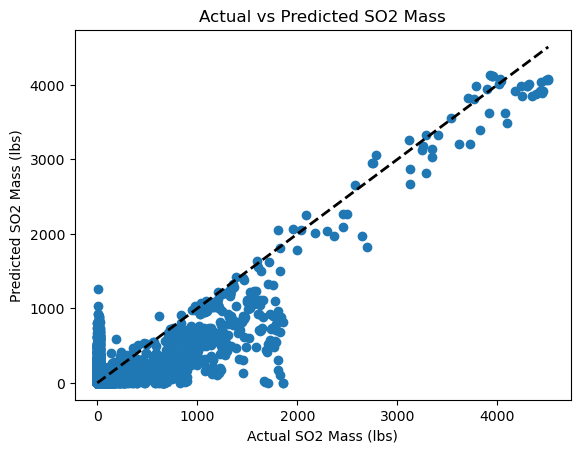

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [21]:
mask_below_500 = y_test < 500
rmse_below_500 = np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500]))

mask_above_500 = y_test >= 500
rmse_above_500 = np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500]))

print(f"RMSE for SO2 Mass below 500 lbs: {rmse_below_500:.4f}")
print(f"RMSE for SO2 Mass above 500 lbs: {rmse_above_500:.4f}")

RMSE for SO2 Mass below 500 lbs: 15.8997
RMSE for SO2 Mass above 500 lbs: 540.5878


R^2 Score: 0.9718
Mean Squared Error (MSE): 72.7744
Root Mean Squared Error (RMSE): 8.5308
Normalized RMSE (by std): 0.1678


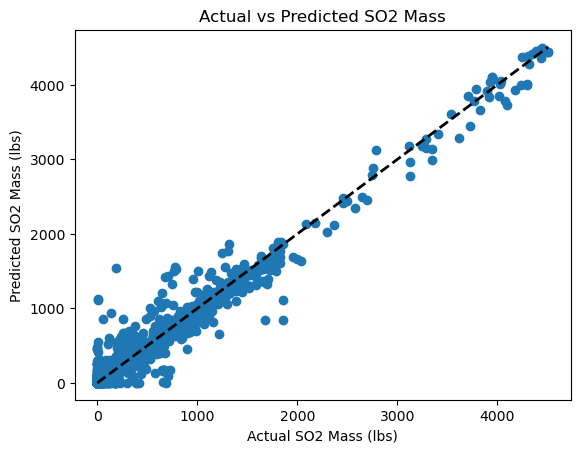

In [ ]:
# model with default parameters (with lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [16]:
mask_below_500 = y_test < 500
rmse_below_500 = np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500]))

mask_above_500 = y_test >= 500
rmse_above_500 = np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500]))

print(f"RMSE for SO2 Mass below 500 lbs: {rmse_below_500:.4f}")
print(f"RMSE for SO2 Mass above 500 lbs: {rmse_above_500:.4f}")

RMSE for SO2 Mass below 500 lbs: 6.0430
RMSE for SO2 Mass above 500 lbs: 180.4096


<h6>HPO - Optuna Trials</h6>

In [ ]:
# default parameters for comparison
# optimization has bias variance tradeoff, see documentation: https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html

default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "tree_method": "hist", # approximation (faster, but not exact, should change on final run)
    "device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

In [ ]:
# objective function for optuna
def objective(trial):
    print(f"Starting trial {trial.number}")

    params = {
        "max_depth": trial.suggest_int("max_depth", 4, 25),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.25),
        "subsample": trial.suggest_float("subsample", 0.3, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 0.5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 0.2),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 6.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
        "tree_method": "hist",
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        #"device": "cuda"  # or "cpu"
    }

    tscv = TimeSeriesSplit(n_splits=5)
    rmse_folds = []
    best_iterations = []

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
        current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
        current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]

        current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
        current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

        evals_result = {}
        model = xgb.train(
            params,
            current_dtrain,
            num_boost_round=1000,
            evals=[(current_dtest, "validation")],
            early_stopping_rounds=20,
            verbose_eval=False, # prevents printing at each boosting stage
            evals_result=evals_result
        )

        best_iterations.append(model.best_iteration)
        # Get last RMSE from evals_result
        fold_rmse = evals_result["validation"]["rmse"][model.best_iteration - 1] # (0-indexed)
        rmse_folds.append(fold_rmse)

        print(f"Fold {fold+1} rmse: {fold_rmse:.4f} best_iteration: {model.best_iteration}")

    avg_rmse = np.mean(rmse_folds)
    avg_best_iter = int(np.mean(best_iterations))

    print(f"Trial {trial.number} avg RMSE: {avg_rmse:.4f}, avg best_iteration: {avg_best_iter}")

    # manually store the avg best boosting rounds and full list of rmse folds (we output the avg rmse separately)
    trial.set_user_attr("best_iteration", avg_best_iter)
    trial.set_user_attr("fold_rmses", rmse_folds)

    return avg_rmse


In [ ]:
study = optuna.create_study(study_name="HPT 22.06.25 18:04", storage="sqlite:///optuna_studies.db", direction="minimize")
study.optimize(objective, n_trials=50) 
print("Best params:", study.best_params)

In [ ]:
study = optuna.load_study(
    study_name="HPT 22.06.25 18:04", 
    storage="sqlite:///optuna_studies.db"
)

# Get the best 5 trials
sorted_trials = sorted(
    [t for t in study.trials if t.value is not None], 
    key=lambda t: t.value
)

for i, trial in enumerate(sorted_trials[:5], 1):
    print(f"\nTrial {i}:")
    print(f"  Value (Objective): {trial.value}")
    print(f"  Number: {trial.number}")
    print(f"  Params:")
    for key, val in trial.params.items():
        print(f"    {key}: {val}")
    print(f"best_iteration: {trial.user_attrs.get("best_iteration")}")

second_best_params = sorted_trials[1]



Trial 1:
  Value (Objective): 9.745089838254874
  Number: 43
  Params:
    max_depth: 14
    learning_rate: 0.01070681077554956
    subsample: 0.318354394879375
    colsample_bytree: 0.777646548524244
    gamma: 0.3607772120989284
    reg_alpha: 0.0108703758177803
    reg_lambda: 0.38740560311398076
    min_child_weight: 7
best_iteration: 570

Trial 2:
  Value (Objective): 9.764771259078591
  Number: 36
  Params:
    max_depth: 14
    learning_rate: 0.028307079329367588
    subsample: 0.5346591526735095
    colsample_bytree: 0.755707012641865
    gamma: 0.32794467494879476
    reg_alpha: 0.03674279467914575
    reg_lambda: 1.067013332785789
    min_child_weight: 15
best_iteration: 243

Trial 3:
  Value (Objective): 9.767127299776904
  Number: 51
  Params:
    max_depth: 14
    learning_rate: 0.010448475834795221
    subsample: 0.47530695004986934
    colsample_bytree: 0.7956950970651904
    gamma: 0.3060105397027625
    reg_alpha: 0.020536194292598522
    reg_lambda: 0.105707880825134

In [23]:
study = optuna.load_study(
    study_name="HPT 22.06.25 18:04", 
    storage="sqlite:///optuna_studies.db"
)

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

# HPO visualizations
fig1 = vis.plot_param_importances(study)
fig2 = vis.plot_optimization_history(study)
fig3 = vis.plot_slice(study)

# update font to Times New Roman
for fig in [fig1, fig2, fig3]:
    fig.update_layout(font=dict(family="Times New Roman", size=14)) 
    fig.show()

Best params: {'max_depth': 14, 'learning_rate': 0.01070681077554956, 'subsample': 0.318354394879375, 'colsample_bytree': 0.777646548524244, 'gamma': 0.3607772120989284, 'reg_alpha': 0.0108703758177803, 'reg_lambda': 0.38740560311398076, 'min_child_weight': 7}
Best value (RMSE): 9.745089838254874
570


<h6>HPO - Model</h6>

In [36]:
# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"),
    "tree_method": "hist",
    #"device": "cuda", # use gpu or cpu
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}

In [ ]:
# second best params found
second_best_hpo_params = {
    **second_best_params.params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"),
    "tree_method": "hist",
    #"device": "cuda", # use gpu or cpu
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}


In [ ]:
default_params = {
    "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    "tree_method": "auto" # automatically chooses exact or approximation method based on data size
}

R^2 Score: 0.9833
Mean Squared Error (MSE): 61.3581
Root Mean Squared Error (RMSE): 7.8331


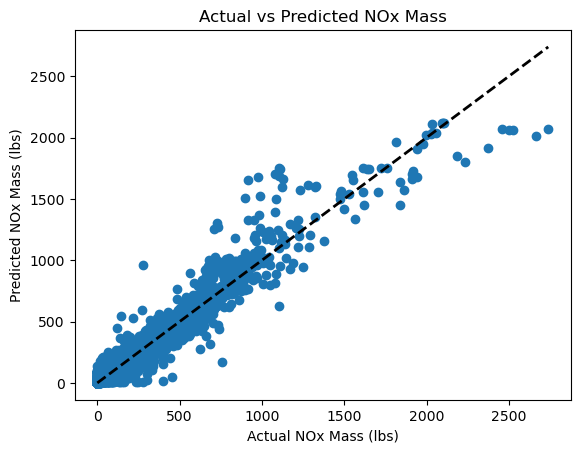

In [ ]:
# model with second best (less boost rounds) hpo parameters (with lags, no unmeasured data)

xgb_hpo_model = xgb.train(params=second_best_hpo_params, dtrain=dtrain, num_boost_round=254)

# dump model
xgb_hpo_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_hpo_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9834
Mean Squared Error (MSE): 60.9311
Root Mean Squared Error (RMSE): 7.8058


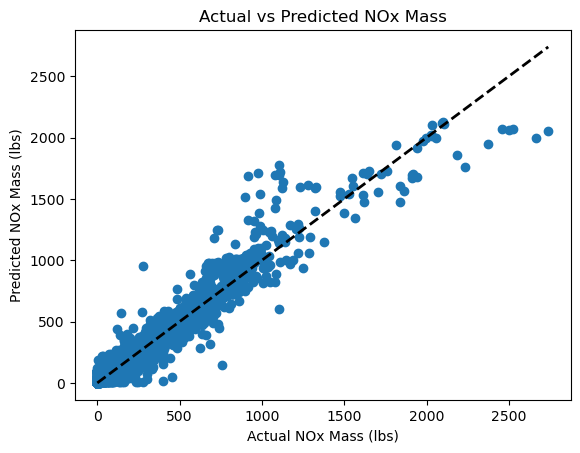

In [ ]:
# model with best hpo parameters (no unmeasured data)

xgb_hpo_model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=570)

# dump model
#xgb_hpo_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained/Models/xgb_hpo_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [22]:
# load saved models
xgb_default_model_with_lags = xgb.Booster()
xgb_default_model_with_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model(("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured.json"))

In [ ]:
xgb_hpo_model = xgb.Booster()
xgb_hpo_model.load_model("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/xgb_hpo_model_ny_with_lags_no_unmeasured.json")

<h3>XGB (model-specific)</h3>

<h5>Default Params</h5>

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

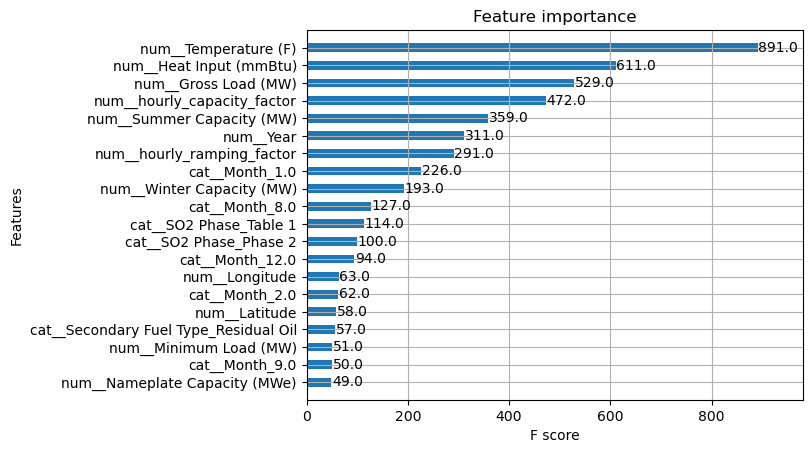

In [19]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

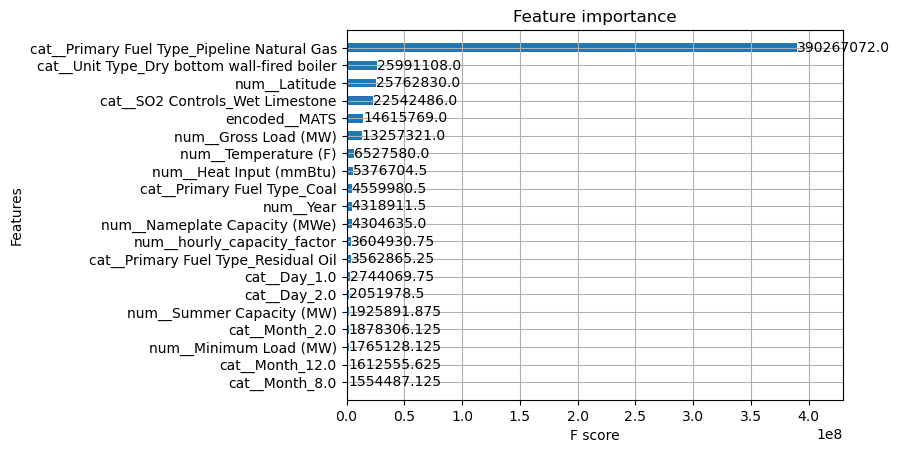

In [20]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

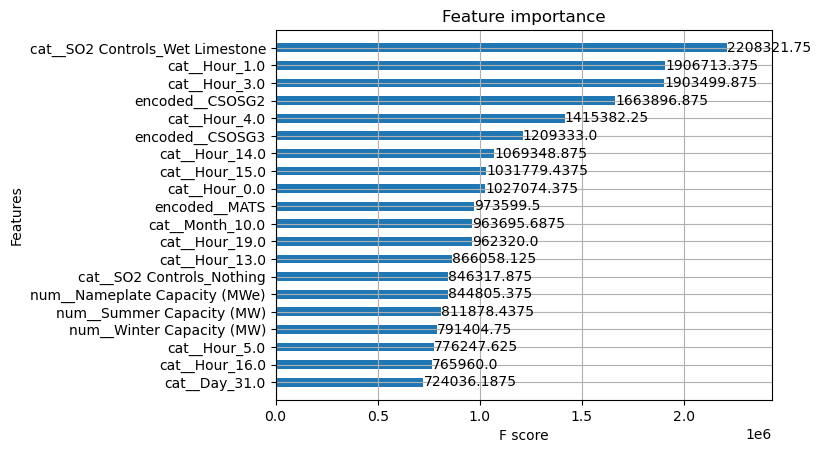

In [21]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_default_model, 
    importance_type='cover', 
    max_num_features=20,      
    height=0.5,
    show_values=True,
    grid=True
)

<h5>HPO Params</h5>

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

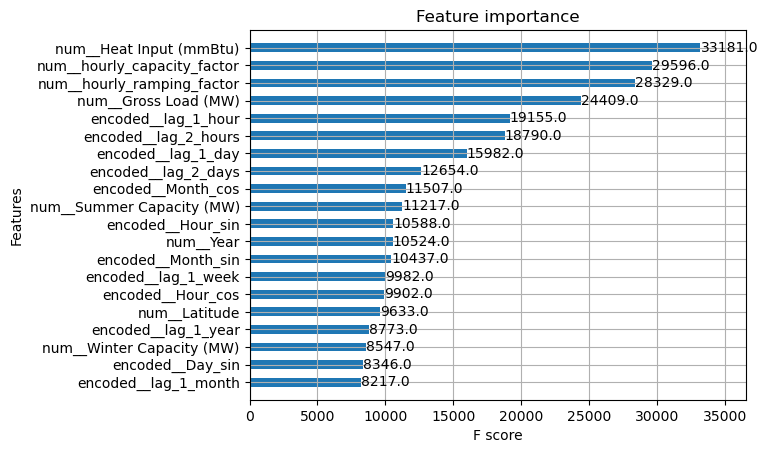

In [12]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_hpo_model, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

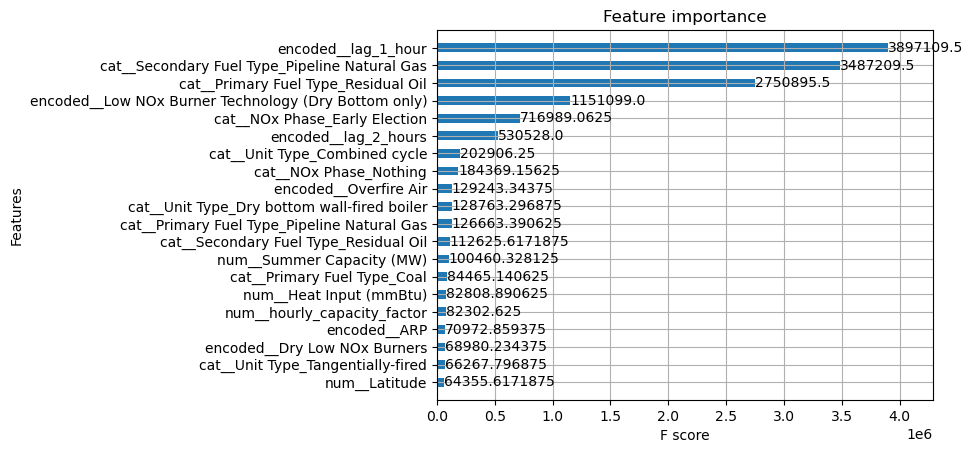

In [13]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_hpo_model, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

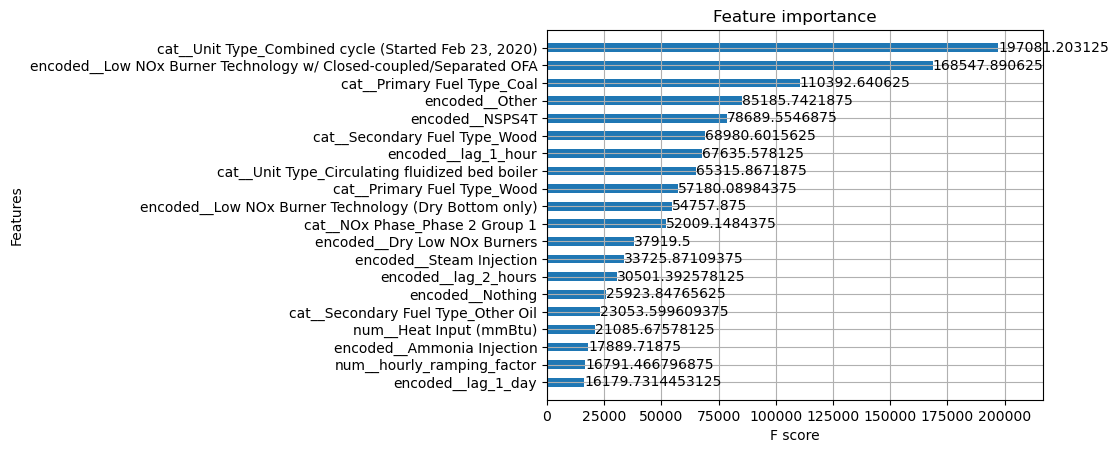

In [17]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_hpo_model, 
    importance_type='cover', 
    max_num_features=20,      
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Partial Dependence Plots</h3>

<h3>Permutation Importance</h3>

<h4>Default Params</h4>

In [20]:
xgb_default_model = xgb.Booster()
xgb_default_model.load_model("xgb_default_model_ny.json")

In [22]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model

In [23]:
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_test")


In [24]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_mean_squared_error')

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)


,feature,importance_mean,importance_std
30,num__Heat Input (mmBtu),4211.327564,7.920819
73,encoded__lag_1_hour,2744.528883,20.343737
29,num__Gross Load (MW),790.022592,1.839927
34,num__hourly_capacity_factor,454.371509,6.923041
33,num__Nameplate Capacity (MWe),295.352342,1.966193
...,...,...,...
41,encoded__Combustion Modification/Fuel Reburning,0.000000,0.000000
79,encoded__lag_1_year,-0.072600,0.081690
68,encoded__Hour_cos,-0.278409,0.233878
78,encoded__lag_1_month,-0.310213,0.263384


<h4>Ungrouped</h4>

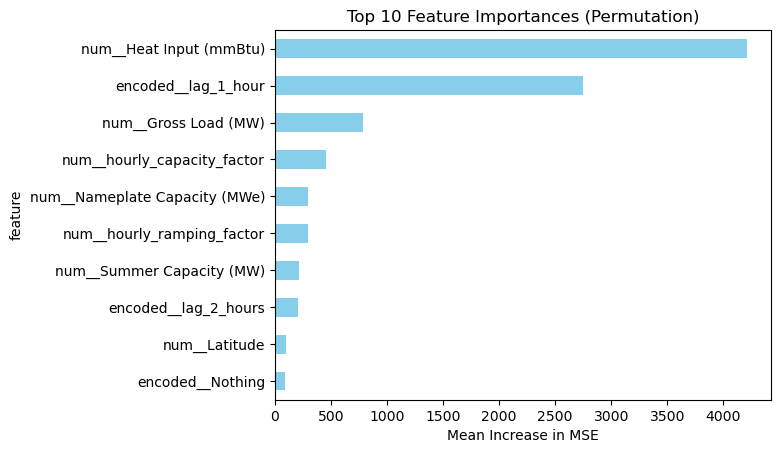

In [25]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


In [26]:
# num features
num_features = ['num__Gross Load (MW)',
                 'num__Heat Input (mmBtu)', 
                 'num__Latitude', 
                 'num__Longitude', 
                 'num__Nameplate Capacity (MWe)',
                   'num__hourly_capacity_factor', 
                   'num__hourly_ramping_factor', 
                   'num__Summer Capacity (MW)', 
                   'num__Winter Capacity (MW)', 
                   'num__Minimum Load (MW)'] # we ignore day, hour, month, year

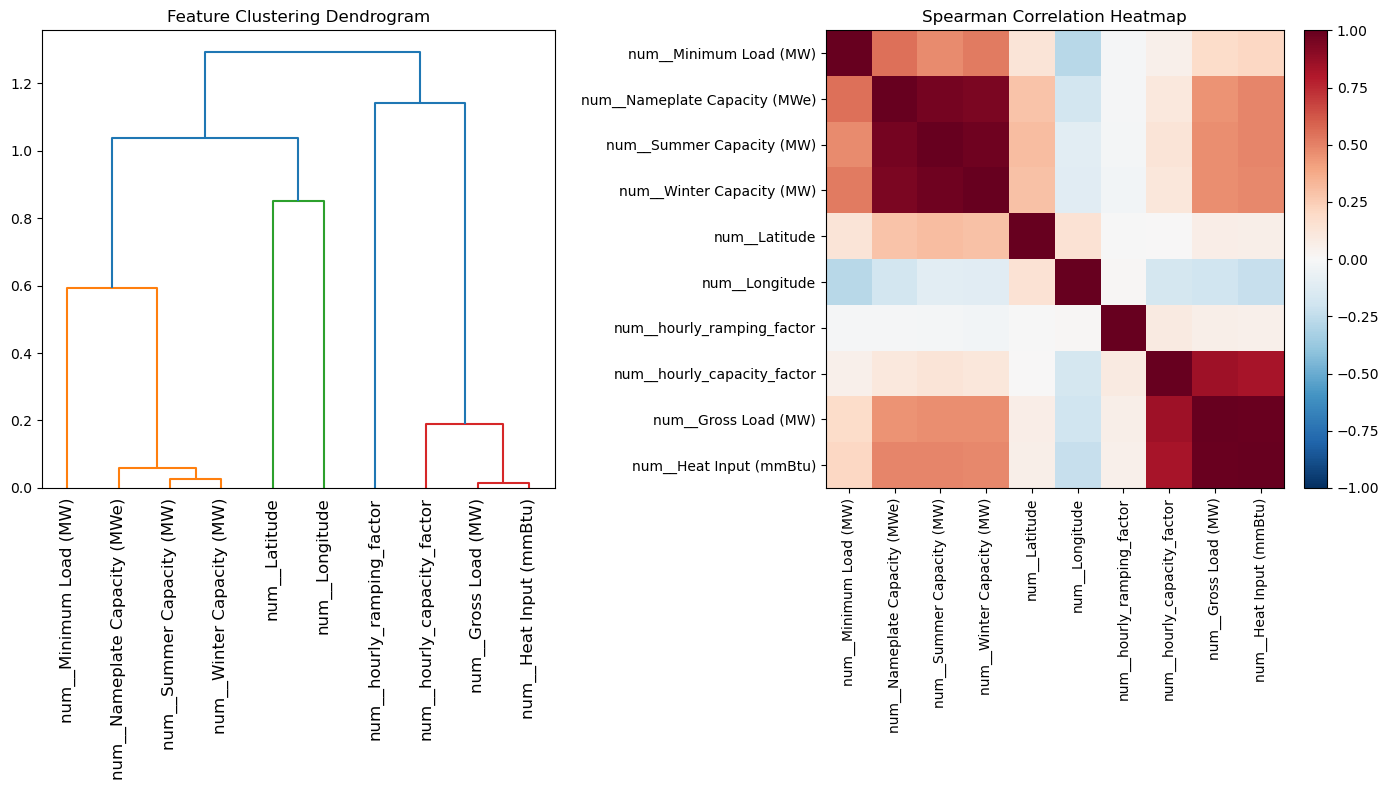

In [27]:
# group features systematically (cluster on correlation)

X_subset = X_test[num_features]
X_subset = X_subset.dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

# Compute Spearman correlation matrix on selected features
corr = spearmanr(X_subset).correlation

# Make symmetric and fill diagonal with 1s
corr = (corr + corr.T) / 2
np.fill_diagonal(corr, 1)

# Convert correlation to distance matrix for clustering
distance_matrix = 1 - np.abs(corr)
dist_linkage = hierarchy.ward(squareform(distance_matrix))

# Plot dendrogram
dendro = hierarchy.dendrogram(
    dist_linkage, labels=X_subset.columns.to_list(), ax=ax1, leaf_rotation=90
)
dendro_idx = np.arange(len(dendro["ivl"]))

# Plot reordered heatmap of correlations
im = ax2.imshow(corr[dendro["leaves"], :][:, dendro["leaves"]],
                cmap='RdBu_r', vmin=-1, vmax=1)
ax2.set_xticks(dendro_idx)
ax2.set_yticks(dendro_idx)
ax2.set_xticklabels(dendro["ivl"], rotation=90)
ax2.set_yticklabels(dendro["ivl"])

# Add colorbar
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

ax1.set_title("Feature Clustering Dendrogram")
ax2.set_title("Spearman Correlation Heatmap")

plt.tight_layout()
plt.show()

# distance here is calculated as 1 - Spearman correlation coefficient


In [ ]:
# select only one feature per group of features with distance <0.2 -> Heat Input, Nameplate Capacity (MWe)

In [29]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_train")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_test")

In [30]:
# group features below threshold of 0.2 (over 80% correlation) and retrain

X_train = X_train.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])
X_test = X_test.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])

# Convert to DMatrix for XGBoost
dtrain = xgb.DMatrix(X_train, label=y_train) 
dtest = xgb.DMatrix(X_test, label=y_test)

R^2 Score: 0.9794
Mean Squared Error (MSE): 75.7565
Root Mean Squared Error (RMSE): 8.7038


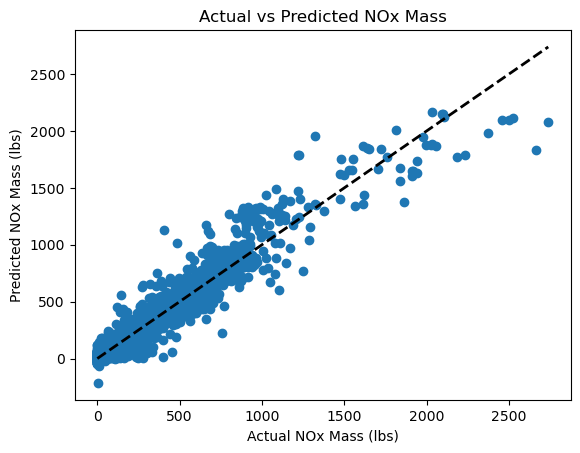

In [ ]:
# Model with default parameters and grouped features (with lags, no unmeasured data)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest)
y_test = dtest.get_label()
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [34]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model

In [35]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_mean_squared_error')

In [36]:
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

print(importance_df)


                              feature  importance_mean  importance_std
29            num__Heat Input (mmBtu)      2521.251736       18.969534
69                encoded__lag_1_hour      2490.092606        8.547923
70               encoded__lag_2_hours       319.698196        0.930906
33         num__hourly_ramping_factor       316.903995        1.990838
32      num__Nameplate Capacity (MWe)       305.800272        1.545558
..                                ...              ...             ...
74               encoded__lag_1_month        -0.217195        0.126999
68                 encoded__Month_cos        -0.252525        0.618682
13  cat__Unit Type_Tangentially-fired        -0.697302        0.153008
66                   encoded__Day_cos        -1.132652        0.368939
63                  encoded__Hour_sin        -1.441972        0.267040

[76 rows x 3 columns]


<h4>Grouped</h4>

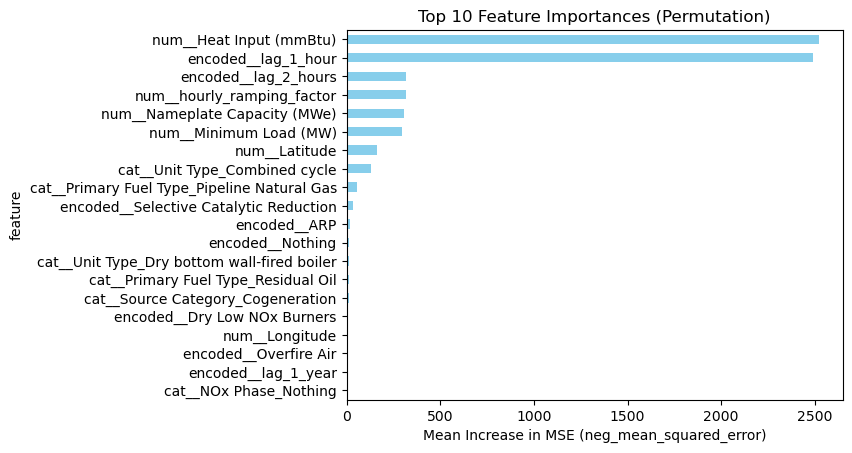

In [38]:
importance_df.head(20).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE (neg_mean_squared_error)')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

<h4>Using Default Params</h4>

<h5>No Lag</h5>

In [23]:
explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [24]:
shap_values = explainer(X_test, approximate=False)

In [25]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl")

C:\Users\marce\AppData\Local\Temp\ipykernel_40096\3056679692.py:15: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\marce\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


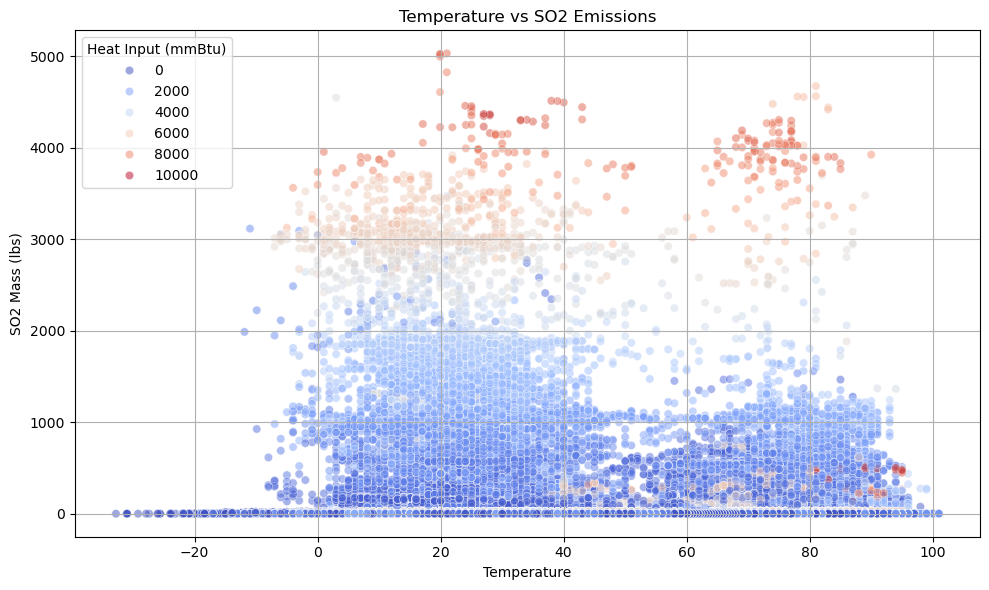

In [32]:

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=campd_df,
    x='Temperature (F)',
    y='SO2 Mass (lbs)',
    hue='Heat Input (mmBtu)', 
    palette='coolwarm',
    alpha=0.5
)

plt.title('Temperature vs SO2 Emissions')
plt.xlabel('Temperature')
plt.ylabel('SO2 Mass (lbs)')
plt.grid(True)
plt.tight_layout()
plt.show()

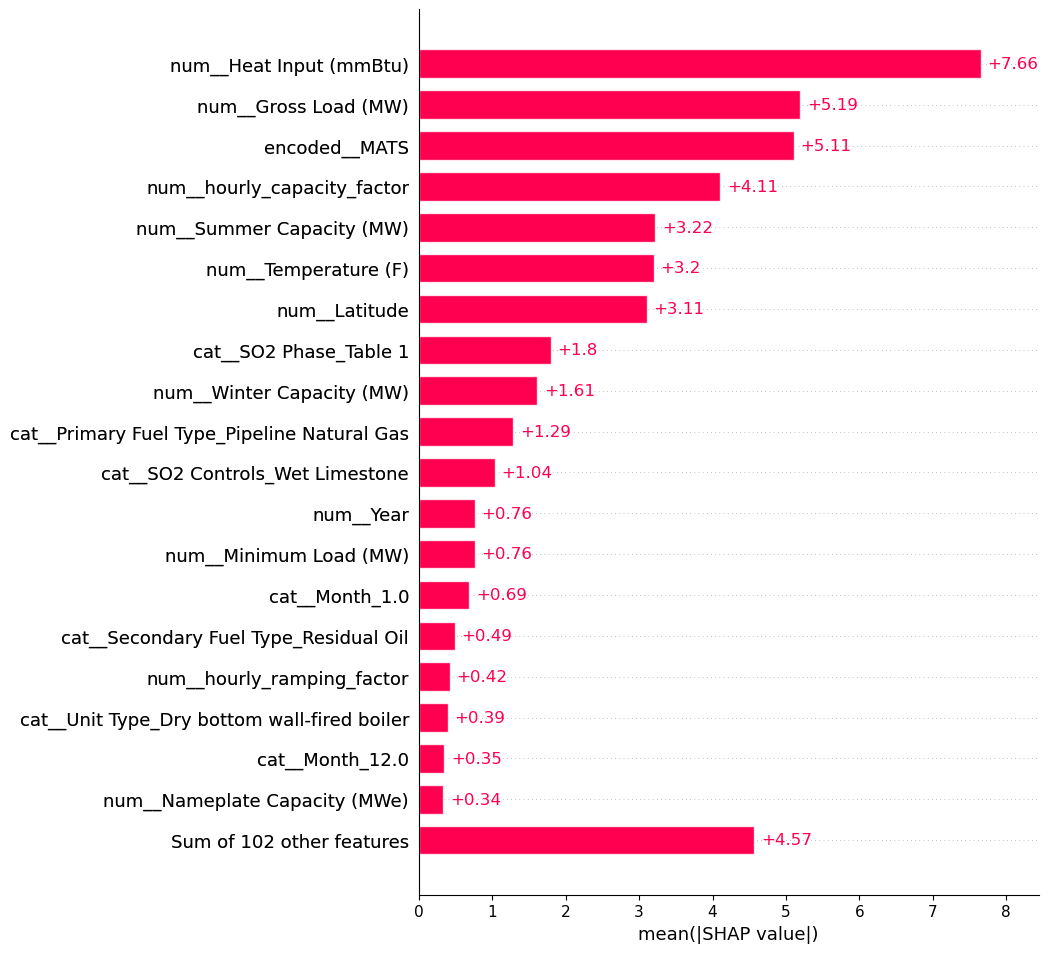

In [26]:
shap.plots.bar(shap_values, max_display=20)

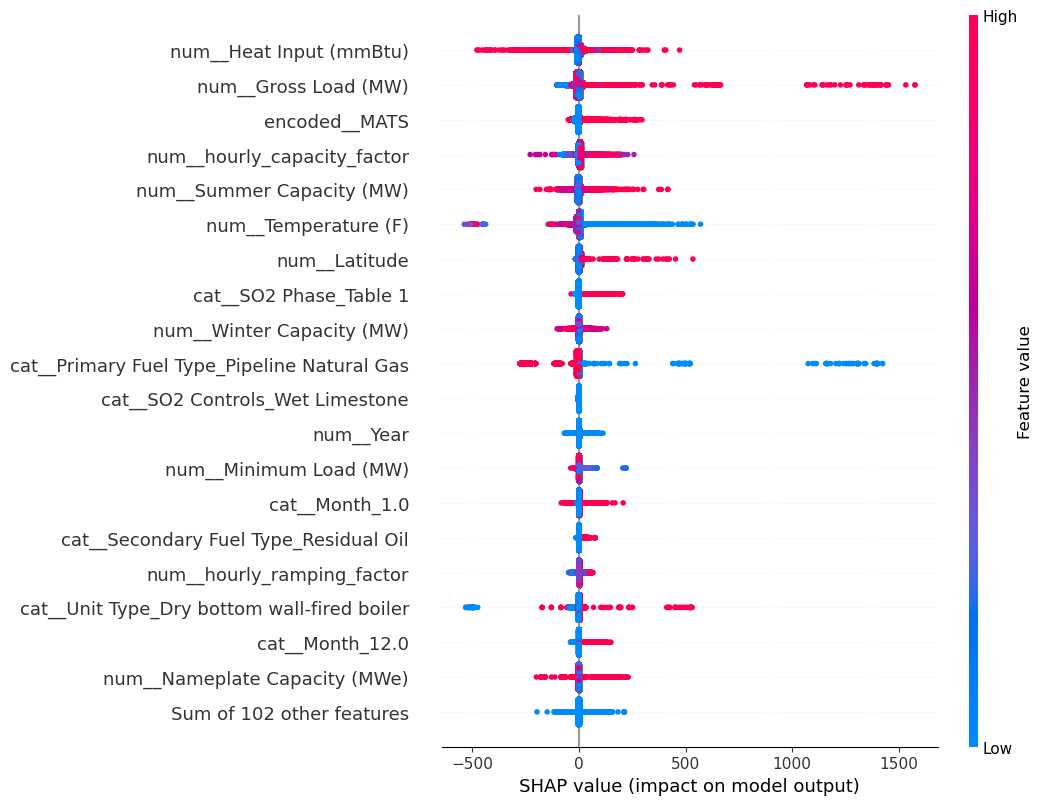

In [33]:
shap.plots.beeswarm(shap_values, max_display=20)

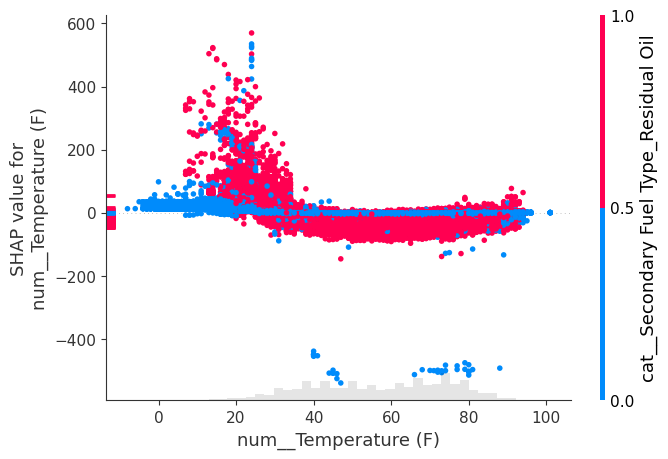

In [ ]:
# we find the same relationship between Temp, Heat Input, and Secondary Fuel Residual Oil here

shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"cat__Secondary Fuel Type_Residual Oil"])

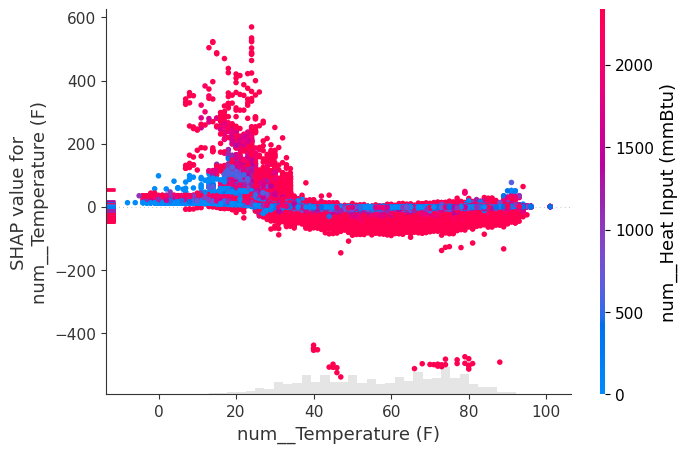

In [35]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

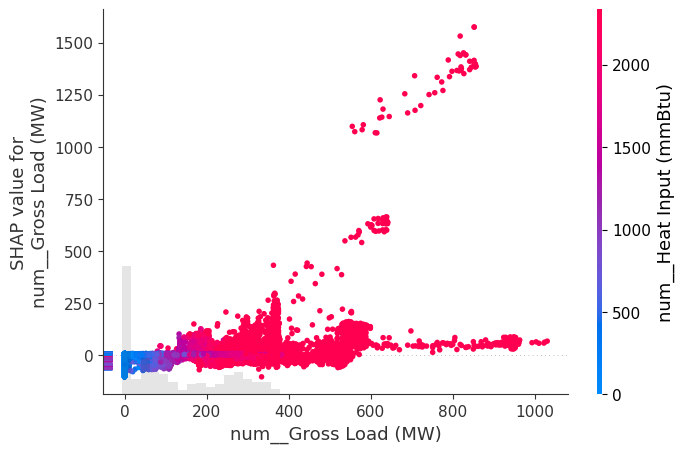

In [34]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

In [66]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "SO2 Phase": [
        'cat__SO2 Phase_Nothing',
        'cat__SO2 Phase_Phase 2',
        'cat__SO2 Phase_Table 1',
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Control Technologies": [
    'cat__SO2 Controls_Dry Lime FGD',
    'cat__SO2 Controls_Nothing',
    'cat__SO2 Controls_Wet Limestone'
    ],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ]
}

In [ ]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


<h5>With Lag</h5>

In [35]:
explainer = shap.TreeExplainer(xgb_default_model)

In [ ]:
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)

In [36]:
shap_values = explainer(X_test, approximate=False)

In [39]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl']

In [50]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/SO2/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl")

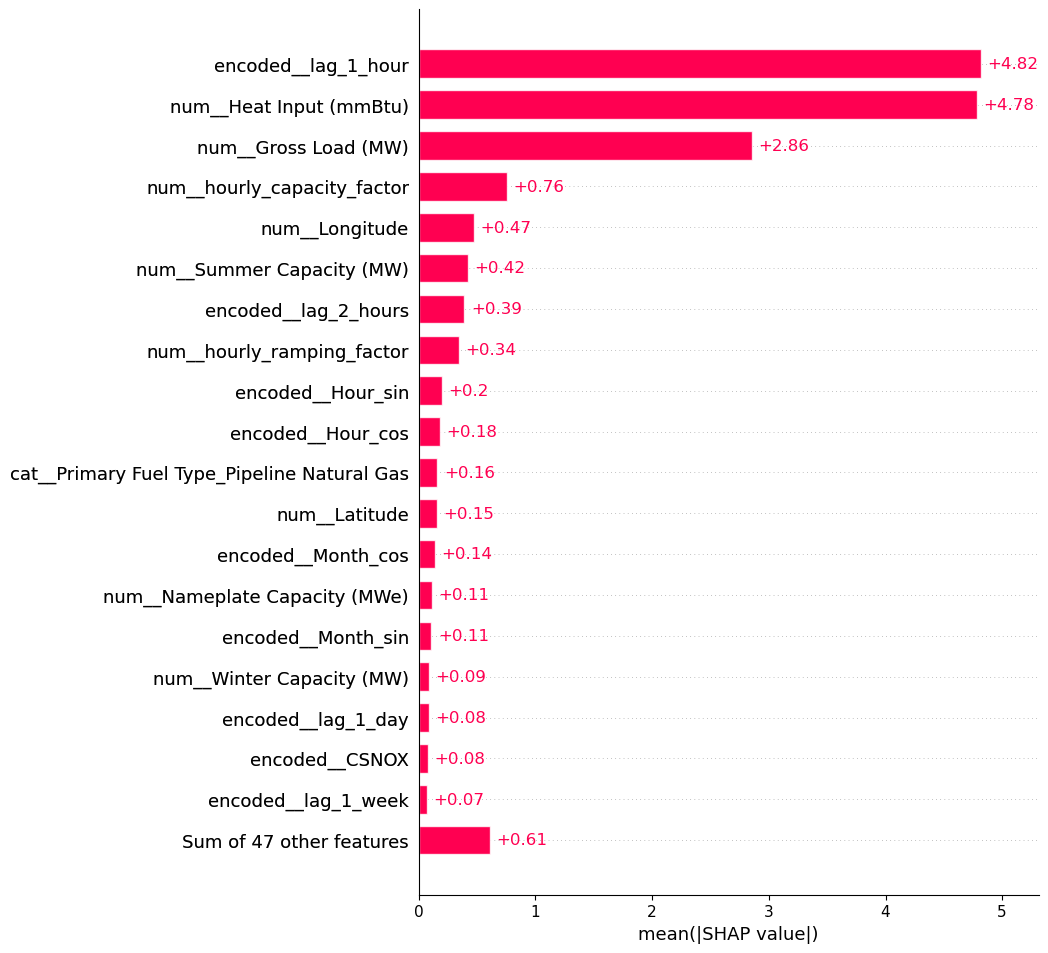

In [51]:
shap.plots.bar(shap_values, max_display=20)

In [ ]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "SO2 Phase": [
        'cat__SO2 Phase_Nothing',
        'cat__SO2 Phase_Phase 2',
        'cat__SO2 Phase_Table 1',
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Control Technologies": [
    'cat__SO2 Controls_Dry Lime FGD',
    'cat__SO2 Controls_Nothing',
    'cat__SO2 Controls_Wet Limestone'
    ],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ],

    "Lag Features": [
        'encoded__lag_1_hour',
        'encoded__lag_2_hours',
        'encoded__lag_1_day',
        'encoded__lag_2_days',
        'encoded__lag_1_week',
        'encoded__lag_1_month',
        'encoded__lag_1_year'
    ]
}

In [ ]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


In [ ]:
shap.plots.waterfall(shap_values[0], max_display=20)

In [ ]:
# global visualizations

# shap.plots.bar(shap_values) # mean absolute value of each feature over all rows
# shap.plots.bar(shap_values.abs.max(0)) # gives max absolute values of features e. g. if features occur infrequently, but have significant effects
# shap.plots.beeswarm(shap_values) # beeswarm plot -> gives context on relationships of high and low feature values to SHAP values

# deal with clustering
# clustering = shap.utils.hclust(X_adult, y_adult)
# shap.plots.bar(shap_values, clustering=clustering)
# shap.plots.bar(shap_values, clustering=clustering, clustering_cutoff=1) # sets distance threshold for clusters, lower values will create smaller clusters

# shap.plots.scatter(shap_values, ylabel="SHAP value") # scatter plots between feature and shap values

<h4>Using HPO parameters</h4>

In [4]:
explainer = shap.TreeExplainer(xgb_hpo_model)

In [5]:
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)

In [6]:
shap_values = explainer(X_test, approximate=True) # need to approximate because otherwise it is to computationally expensive for the hpo model

In [7]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_ny_with_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_ny_with_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_ny_with_lags_no_unmeasured.pkl")

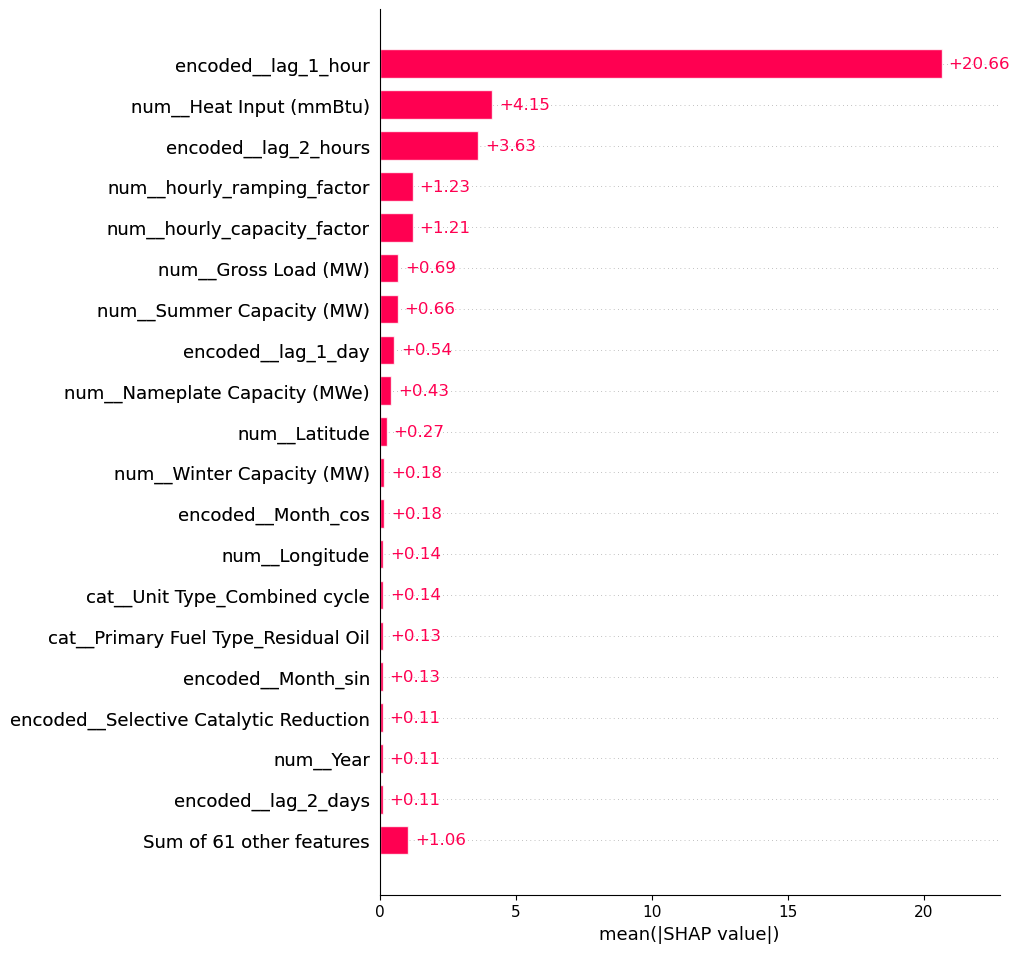

In [8]:
shap.plots.bar(shap_values, max_display=20)

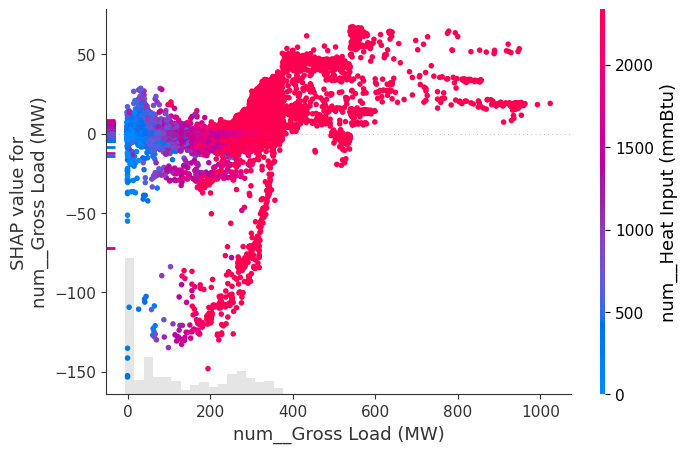

In [9]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


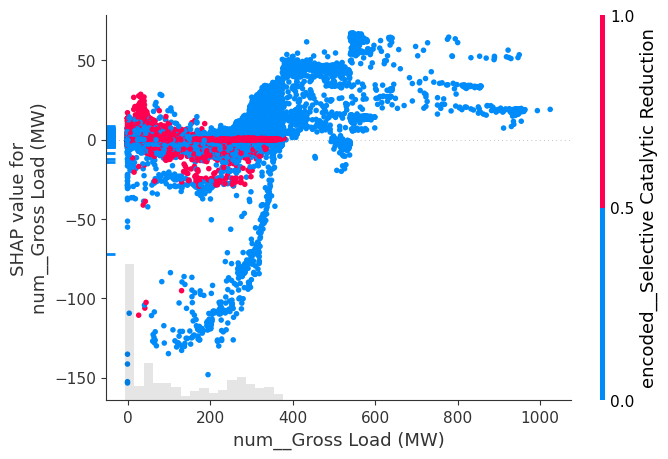

In [10]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"encoded__Selective Catalytic Reduction"])


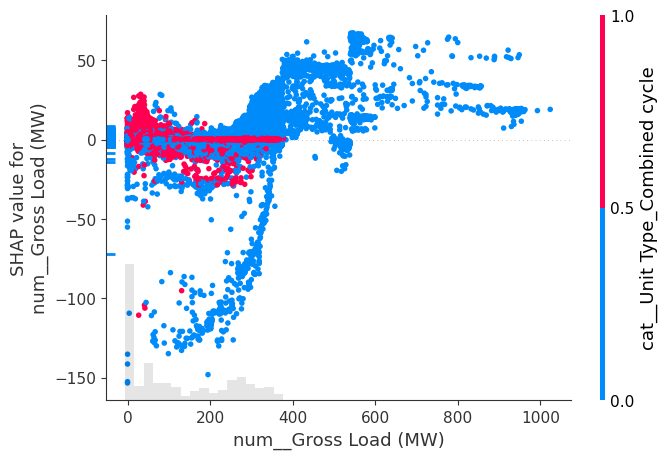

In [11]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"cat__Unit Type_Combined cycle"])  


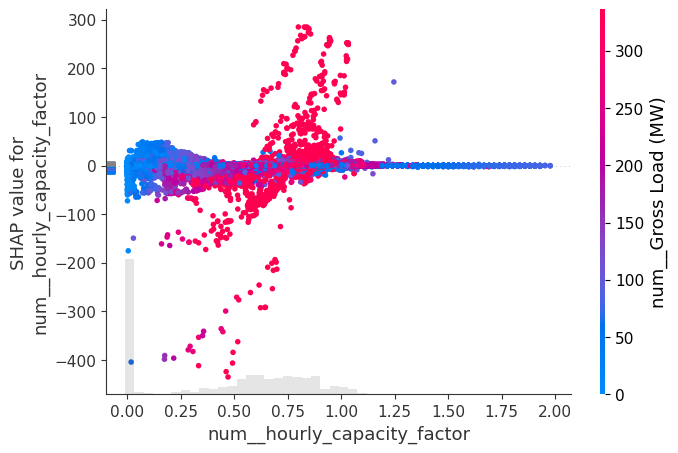

In [12]:
shap.plots.scatter(shap_values[:,"num__hourly_capacity_factor"], color=shap_values[:,"num__Gross Load (MW)"])


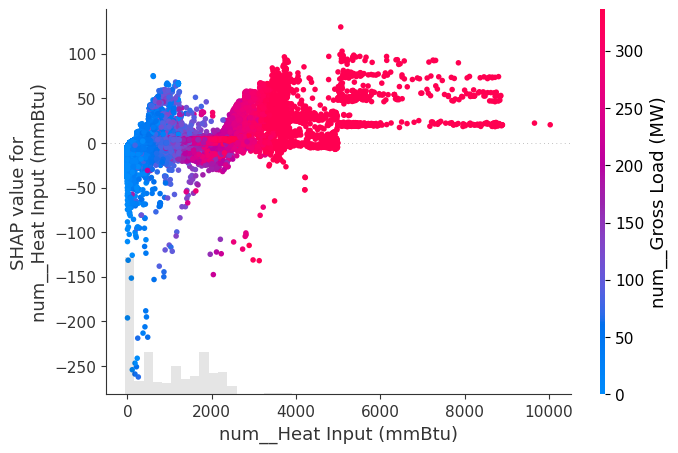

In [13]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])


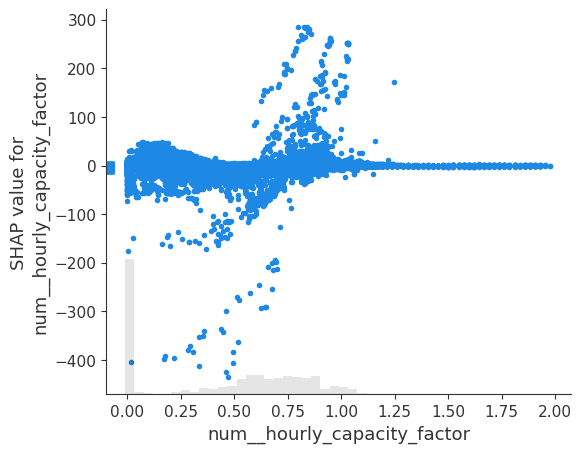

In [14]:
shap.plots.scatter(shap_values[:,"num__hourly_capacity_factor"])#, color=shap_values[:,"encoded__Selective Catalytic Reduction"])


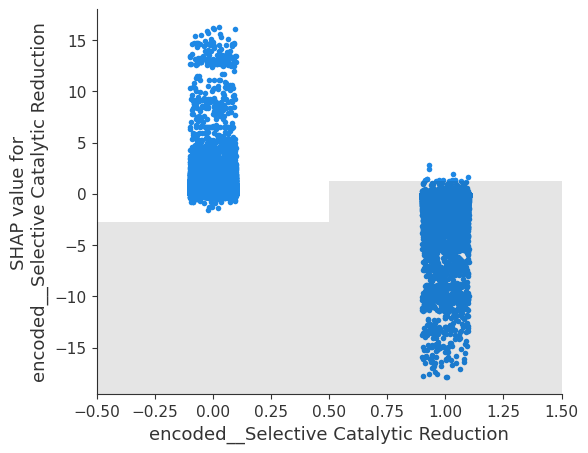

In [15]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"])


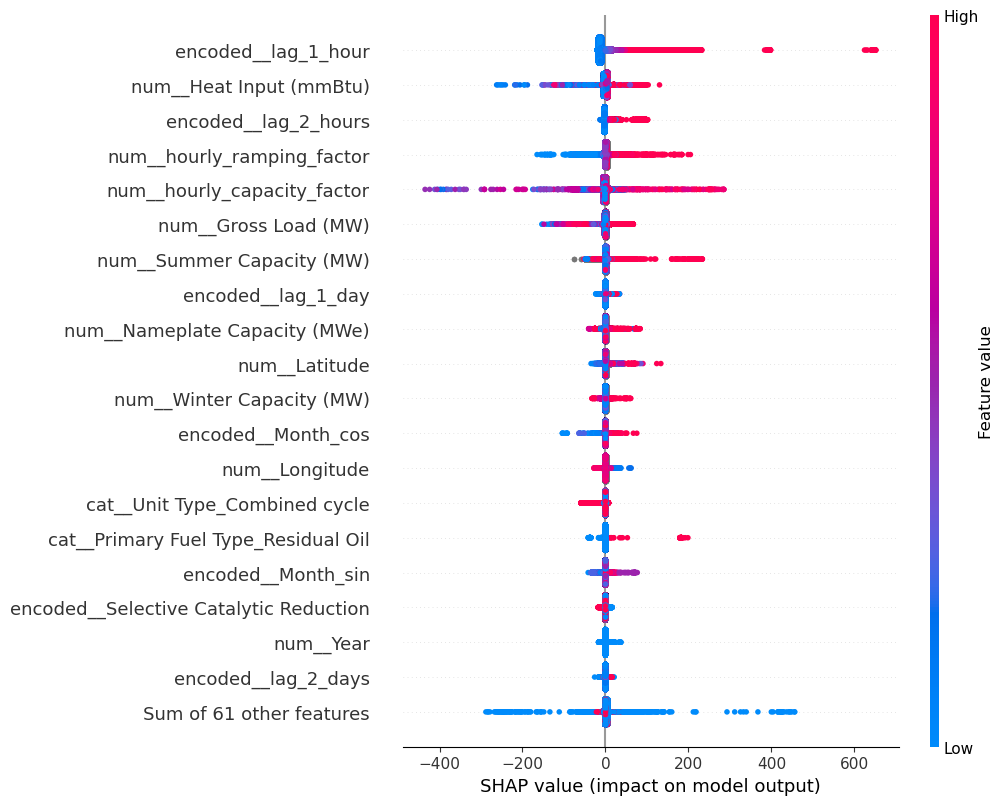

In [16]:
shap.plots.beeswarm(shap_values, max_display=20)


In [ ]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "SO2 Phase": [
        'cat__SO2 Phase_Early Election',
        'cat__SO2 Phase_Nothing',
        'cat__SO2 Phase_Phase 1 Group 1',
        'cat__SO2 Phase_Phase 2 Group 1'
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Control Technologies": [

    ],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ],

    "Lag Features": [
        'encoded__lag_1_hour',
        'encoded__lag_2_hours',
        'encoded__lag_1_day',
        'encoded__lag_2_days',
        'encoded__lag_1_week',
        'encoded__lag_1_month',
        'encoded__lag_1_year'
    ]
}

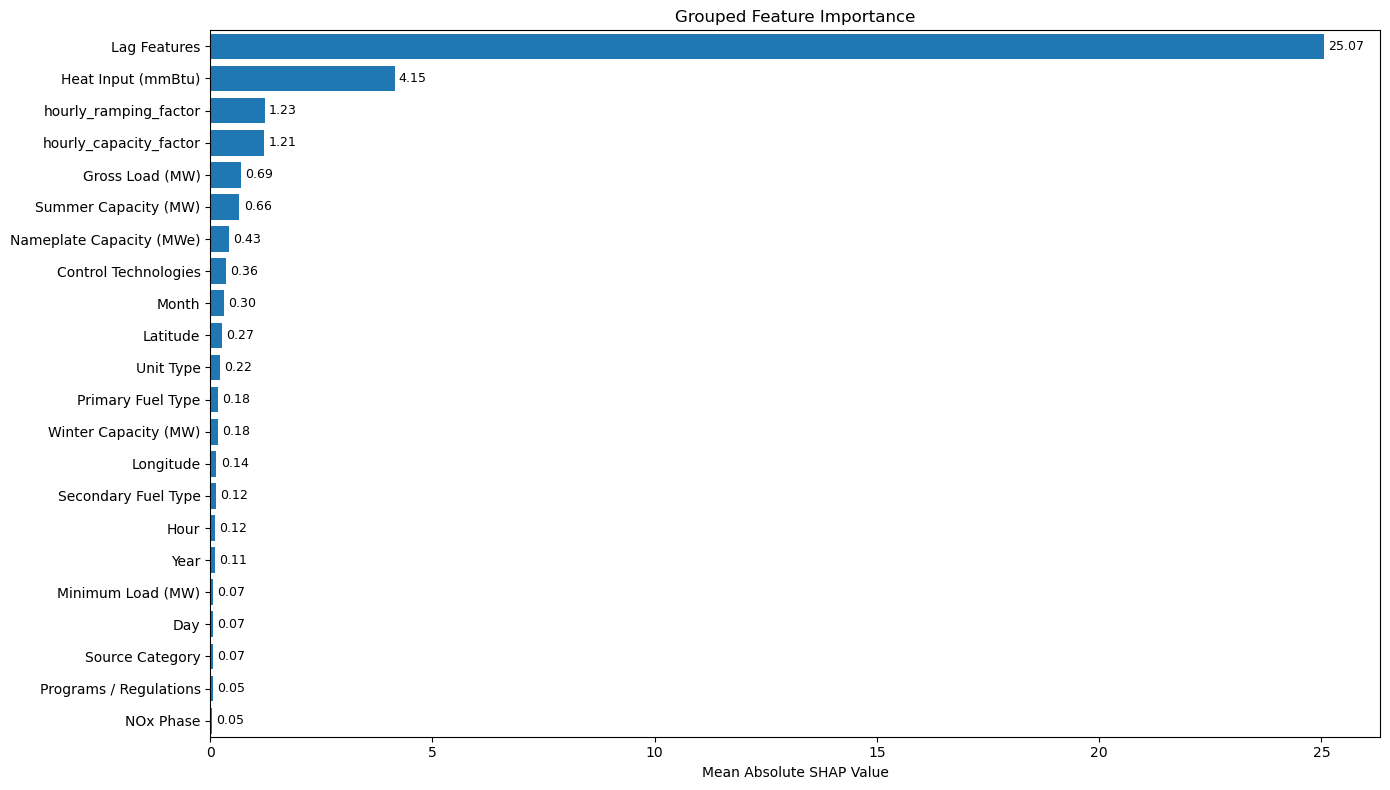

In [18]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


<h3>LIME</h3>